# Position held: individuals with a dated position, per century

In [1]:
import json
import re
import sys

import duckdb
import matplotlib.pyplot as plt
import polars as pl

sys.path.insert(0, '../notebooks_analysis')
from matplotlib.lines import Line2D
from matplotlib.patches import Patch
from shapely import STRtree, points
from shapely.geometry import shape
from style import *

DB_PATH = '../../data/cultura/cultura_enriched_v3.2.duckdb'  # read only: birth years
POSITIONS_PATH = '../../data/raw_data_from_wikidata/wikidata_extraction_scripts_v2/life_locations/position_held_P39_statements.json'  # raw P39 statements
TARGETS_PATH = '../../data/raw_data_from_wikidata/wikidata_extraction_scripts_v2/life_locations/targets.json'  # raw labels of the positions
FIRST_CENTURY, LAST_CENTURY = -500, 1900
CENTURY = 100  # years
EXAMPLE_BIRTH_YEARS = (700, 799)  # century of birth of the example individuals of Figure 3
OCCUPATION_BIRTH_YEARS = (1600, 1699)  # century of birth of the scientists and artists of Figures 4 and 5
OCCUPATIONS = {'Discovery/Science': 'scientists', 'Culture': 'artists', 'Leadership': 'leaders'}  # main meta occupation of the scientists, artists and leaders shown
EXAMPLES = 10  # most-linked individuals shown in each example figure
AGE_LABEL_WIDTH = 11  # years: width of an age label on the time axis; a label overlapping the previous one is pushed to its right
EVENT_COLORS = {'Birth': TEXT, 'Start of first position': PURPLE, 'End of last position': PURPLE, 'First dated work': TEAL, 'Last dated work': TEAL, 'Death': TEXT}
EVENT_LEVELS = [1, -1, 2, -2, 3, -3]  # label heights above and below a timeline, the nearest free one first
LEVEL_HEIGHT = 1.3  # vertical distance between two label heights
LABEL_SPAN = 0.3  # share of the lifetime a label covers on the time axis: a closer label takes another height
COUNTRIES_PATH = '../../data/ne_110m_admin_0_countries.geojson'  # Natural Earth present-day borders
REGIONS = {'China': lambda country: country['ISO_A3'] == 'CHN', 'Europe': lambda country: country['CONTINENT'] == 'Europe'}
MIX_BIRTH_YEARS = (1500, 1599)  # century of birth of the mixed chronology
MIX = [('Europe', 'Discovery/Science', 3), ('Europe', 'Culture', 2), ('Europe', 'Leadership', 1), ('China', 'Culture', 2), ('China', 'Leadership', 2)]  # region, main meta occupation, individuals
MILESTONE_COLORS = {'first work': TEAL, 'first position': NAVY}
SPAN_COLORS = {'Before the first position': ORANGE, 'Positions held (first start → last end)': PURPLE, 'After the last position': GREEN}

pl.Config.set_tbl_rows(40)
apply_style()

## Data
Raw Wikidata position held (P39) statements, deprecated ones dropped. A position counts only with both a start time (P580) and an end time (P582); a position without them, or with a point in time (P585) only, does not count. Individuals are placed in their century of birth (`individual_enriched`, Wikidata or estimated).

In [2]:
def year(value):
    sign, digits = re.match(r'([+-]?)(\d+)-', value['time']).groups()
    return -int(digits) if sign == '-' else int(digits)


raw = json.load(open(POSITIONS_PATH))
positions = pl.DataFrame(
    [
        {'qid': qid, 'position_qid': statement['target'],
         'start_year': year(statement['start']) if statement['start'] else None, 'start_precision': statement['start']['precision'] if statement['start'] else None,
         'end_year': year(statement['end']) if statement['end'] else None, 'end_precision': statement['end']['precision'] if statement['end'] else None,
         'point_in_time': statement['point_in_time'] is not None}
        for qid, statements in raw.items() for statement in statements if statement['rank'] != 'deprecated'
    ],
    schema={'qid': pl.String, 'position_qid': pl.String, 'start_year': pl.Int64, 'start_precision': pl.Int64, 'end_year': pl.Int64, 'end_precision': pl.Int64, 'point_in_time': pl.Boolean},
)
del raw
dated = positions.filter(pl.col('start_year').is_not_null() & pl.col('end_year').is_not_null())
print(f"{positions['qid'].n_unique():,} individuals with a position held, {dated['qid'].n_unique():,} with at least one position with a start and an end")
dated.sample(5, seed=42)

979,289 individuals with a position held, 454,417 with at least one position with a start and an end


qid,position_qid,start_year,start_precision,end_year,end_precision,point_in_time
str,str,i64,i64,i64,i64,bool
"""Q65593540""","""Q65482993""",2014,11,2020,11,false
"""Q21001584""","""Q18171345""",2009,11,2011,11,false
"""Q98247472""","""Q65477748""",2020,11,2026,11,false
"""Q6214979""","""Q81531912""",1873,9,1875,9,false
"""Q65585278""","""Q65192029""",2014,11,2020,11,false


In [3]:
con = duckdb.connect(DB_PATH, read_only=True)
births = con.sql('''
    SELECT entity.qid AS qid, birth_date.year AS birth_year,
           first_work_date.source = 'dated works' AND first_work_date.year < last_work_date.year AS work_period
    FROM   individual_enriched
    WHERE  birth_date.year IS NOT NULL
''').pl()
con.close()
born_per_century = births.group_by((pl.col('birth_year') // CENTURY * CENTURY).alias('century')).agg(pl.len().alias('individuals born'))
print(f'{births.height:,} individuals with a birth year')

7,641,351 individuals with a birth year


## Preprocessing
### Individuals with a dated position, per century of birth

In [4]:
with_dated_position = pl.DataFrame({'qid': dated['qid'].unique()}).join(births, on='qid', how='left')
print(f"{with_dated_position['birth_year'].null_count():,} of {with_dated_position.height:,} individuals with a dated position have no birth year and are left out")

per_century = (
    with_dated_position.drop_nulls('birth_year')
    .group_by((pl.col('birth_year') // CENTURY * CENTURY).alias('century')).agg(pl.len().alias('with a dated position'))
    .join(born_per_century, on='century', how='right')
    .filter(pl.col('century').is_between(FIRST_CENTURY, LAST_CENTURY))
    .with_columns(pl.col('with a dated position').fill_null(0))
    .with_columns((100 * pl.col('with a dated position') / pl.col('individuals born')).round(2).alias('% of individuals born'))
    .select('century', 'individuals born', 'with a dated position', '% of individuals born')
    .sort('century')
)
assert per_century['century'].is_unique().all()
per_century

53,878 of 454,417 individuals with a dated position have no birth year and are left out


century,individuals born,with a dated position,% of individuals born
i64,u32,u32,f64
-500,443,72,16.25
-400,596,104,17.45
-300,702,236,33.62
-200,701,234,33.38
-100,949,166,17.49
0,928,142,15.3
100,1316,96,7.29
200,1718,138,8.03
300,1810,226,12.49


### Dates of the position-held statements
Each statement by the dates it carries: start and end, start only, end only, a point in time only, no date.

In [5]:
dates_carried = positions.with_columns(
    pl.when(pl.col('start_year').is_not_null() & pl.col('end_year').is_not_null()).then(pl.lit('start and end'))
    .when(pl.col('start_year').is_not_null()).then(pl.lit('start only'))
    .when(pl.col('end_year').is_not_null()).then(pl.lit('end only'))
    .when(pl.col('point_in_time')).then(pl.lit('point in time only'))
    .otherwise(pl.lit('no date')).alias('dates')
)
statement_dates = (
    dates_carried.group_by('dates').agg(pl.len().alias('statements'), pl.col('qid').n_unique().alias('individuals'))
    .with_columns((100 * pl.col('statements') / pl.col('statements').sum()).round(1).alias('% of statements'))
    .sort('statements', descending=True)
)
start_only_people = dates_carried.group_by('qid').agg((pl.col('dates') == 'start only').any().alias('start only'), (pl.col('dates') == 'start and end').any().alias('start and end'))
print(f"{start_only_people.filter('start only').height:,} individuals have a position with a start and no end; "
      f"{start_only_people.filter(pl.col('start only') & ~pl.col('start and end')).height:,} of them have no position with both dates")
statement_dates

208,762 individuals have a position with a start and no end; 115,937 of them have no position with both dates


dates,statements,individuals,% of statements
str,u32,u32,f64
"""start and end""",983518,454417,50.5
"""no date""",662594,485169,34.0
"""start only""",284335,208762,14.6
"""end only""",9308,8763,0.5
"""point in time only""",7376,6701,0.4


### Individuals with a dated position and dated works, per century of birth
Dated position: a position with a start and an end. Dated works: first and last dated works in different years (notebook 02).

In [6]:
dated_qids = dated['qid'].unique().implode()
position_and_works = (
    births.with_columns(pl.col('qid').is_in(dated_qids).alias('dated position'), pl.col('work_period').fill_null(False).alias('dated works'))
    .with_columns((pl.col('dated position') & pl.col('dated works')).alias('both'))
    .group_by((pl.col('birth_year') // CENTURY * CENTURY).alias('century'))
    .agg(pl.col('dated position').sum(), pl.col('dated works').sum(), pl.col('both').sum())
    .filter(pl.col('century').is_between(FIRST_CENTURY, LAST_CENTURY))
    .sort('century')
)
position_and_works

century,dated position,dated works,both
i64,u32,u32,u32
-500,72,11,1
-400,104,4,0
-300,236,2,1
-200,234,1,1
-100,166,8,3
0,142,4,2
100,96,5,2
200,138,2,1
300,226,7,2


### Example individuals
The most-linked individuals (Wikipedia pages) with a dated position and a birth and a death from Wikidata: birth, start of their first position, end of their last position, death, and their first and last dated works (notebook 02) when they have some; no estimated date is shown. Figure 3: everyone born 700–799; scientists, artists and leaders: main meta occupation (as in notebook 02) born 1600–1699, the scientists and artists with dated works spanning more than one year.

In [7]:
position_spans = dated.group_by('qid').agg(
    pl.col('start_year').min().alias('first_position'),
    pl.col('position_qid').sort_by('start_year').first().alias('first_position_qid'),
    pl.col('end_year').max().alias('last_position'),
    pl.col('position_qid').sort_by('end_year').last().alias('last_position_qid'),
    pl.len().alias('positions'),
)
con = duckdb.connect(DB_PATH, read_only=True)
con.register('position_spans', position_spans.to_arrow())
con.sql('''
    CREATE TEMP TABLE main_occupation AS
    WITH held AS (
        SELECT individual.entity.qid AS qid, unnest(individual.occupation).entity.qid AS occupation_qid, generate_subscripts(individual.occupation, 1) AS position
        FROM   individual
        JOIN   position_spans ON position_spans.qid = individual.entity.qid
    ),
    counted AS (
        SELECT held.qid, occupation.meta_occupation AS occupation, count(*) AS occupations, min(held.position) AS first_position
        FROM   held
        JOIN   occupation ON occupation.entity.qid = held.occupation_qid
        WHERE  occupation.meta_occupation IN ('Culture', 'Discovery/Science', 'Leadership', 'Sports/Games')
        GROUP BY ALL
    )
    SELECT qid, occupation
    FROM   counted
    QUALIFY row_number() OVER (PARTITION BY qid ORDER BY occupations DESC, first_position) = 1
''')


def example_lives(birth_years, occupation=None):
    filters = "individual_enriched.birth_date.source = 'wikidata' AND individual_enriched.death_date.source = 'wikidata'"
    if occupation is not None:
        filters += " AND main_occupation.occupation = $occupation"
    if occupation in ('Culture', 'Discovery/Science'):
        filters += " AND individual_enriched.first_work_date.source = 'dated works' AND individual_enriched.first_work_date.year < individual_enriched.last_work_date.year"

    params = {'first': birth_years[0], 'last': birth_years[1], 'examples': EXAMPLES} | ({} if occupation is None else {'occupation': occupation})
    return con.sql(f'''
        SELECT individual_enriched.entity.qid AS qid,
               individual_enriched.entity.label_en AS name,
               len(individual.sitelink) AS sitelinks,
               individual_enriched.birth_date.year AS birth_year,
               individual_enriched.birth_date.source AS birth_source,
               position_spans.first_position,
               position_spans.first_position_qid,
               position_spans.last_position,
               position_spans.last_position_qid,
               position_spans.positions,
               individual_enriched.death_date.year AS death_year,
               individual_enriched.death_date.source AS death_source,
               individual_enriched.first_work_date.year AS peak_start,
               individual_enriched.last_work_date.year AS peak_end,
               individual_enriched.first_work_date.source AS peak_source
        FROM   individual_enriched
        JOIN   individual ON individual.entity.qid = individual_enriched.entity.qid
        JOIN   position_spans ON position_spans.qid = individual_enriched.entity.qid
        LEFT JOIN main_occupation ON main_occupation.qid = individual_enriched.entity.qid
        WHERE  individual_enriched.birth_date.year BETWEEN $first AND $last
               AND individual_enriched.death_date.year IS NOT NULL AND individual_enriched.entity.label_en IS NOT NULL
               AND {filters}
        ORDER BY sitelinks DESC, qid
        LIMIT  $examples
    ''', params=params).pl().sort('birth_year', descending=True)


examples = {'everyone': example_lives(EXAMPLE_BIRTH_YEARS), **{label: example_lives(OCCUPATION_BIRTH_YEARS, occupation) for occupation, label in OCCUPATIONS.items()}}

candidates = con.sql('''
    WITH citizenship AS (
        SELECT entity.qid AS qid, unnest(country_of_citizenship).entity.qid AS polity_qid
        FROM   individual
    )
    SELECT DISTINCT individual_enriched.entity.qid AS qid,
           individual_enriched.entity.label_en AS name,
           main_occupation.occupation,
           len(individual.sitelink) AS sitelinks,
           individual_enriched.birth_date.year AS birth_year,
           individual_enriched.birth_date.source AS birth_source,
           position_spans.first_position,
           position_spans.first_position_qid,
           position_spans.last_position,
           position_spans.last_position_qid,
           position_spans.positions,
           individual_enriched.death_date.year AS death_year,
           individual_enriched.death_date.source AS death_source,
           individual_enriched.first_work_date.year AS peak_start,
           individual_enriched.last_work_date.year AS peak_end,
           individual_enriched.first_work_date.source AS peak_source,
           place.coordinates.longitude AS longitude,
           place.coordinates.latitude AS latitude
    FROM   individual_enriched
    JOIN   individual ON individual.entity.qid = individual_enriched.entity.qid
    JOIN   position_spans ON position_spans.qid = individual_enriched.entity.qid
    JOIN   main_occupation ON main_occupation.qid = individual_enriched.entity.qid
    JOIN   citizenship ON citizenship.qid = individual_enriched.entity.qid
    JOIN   place ON place.entity.qid = citizenship.polity_qid
    WHERE  individual_enriched.birth_date.year BETWEEN $first AND $last
           AND individual_enriched.birth_date.source = 'wikidata' AND individual_enriched.death_date.source = 'wikidata'
           AND individual_enriched.entity.label_en IS NOT NULL AND place.coordinates.longitude IS NOT NULL
''', params={'first': MIX_BIRTH_YEARS[0], 'last': MIX_BIRTH_YEARS[1]}).pl()
countries = json.load(open(COUNTRIES_PATH))['features']
region_shapes = [(region, shape(country['geometry'])) for country in countries for region, inside in REGIONS.items() if inside(country['properties'])]
spot, shape_index = STRtree([geometry for _, geometry in region_shapes]).query(points(candidates['longitude'].to_numpy(), candidates['latitude'].to_numpy()), predicate='within')
candidates = (
    candidates[spot].with_columns(pl.Series('region', [region_shapes[i][0] for i in shape_index]))
    .drop('longitude', 'latitude').unique()
    .filter(pl.len().over('qid') == 1)
)
examples['mixed'] = pl.concat([
    candidates.filter((pl.col('region') == region) & (pl.col('occupation') == occupation))
    .sort(pl.col('peak_source') == 'dated works', 'sitelinks', descending=True).head(n)
    for region, occupation, n in MIX
]).drop('occupation')

dated_ends = pl.concat([frame.filter(pl.col('peak_source') == 'dated works').select('qid', 'peak_start', 'peak_end') for frame in examples.values()]).unique()
con.register('dated_ends', dated_ends.to_arrow())
work_names = con.sql('''
    WITH dated AS (
        SELECT individual_work.qid,
               coalesce(work.entity.label_en, work.entity.label_non_en) AS work_name,
               'untitled ' || coalesce(work.instance_of[1].label_en, 'work') || ' (' || work.entity.qid || ')' AS untitled_name,
               CASE WHEN list_contains(['day', 'month', 'year', 'decade'], work.inception.precision) THEN work.inception ELSE work.publication_date END AS date
        FROM   individual_work
        JOIN   work ON work.entity.qid = individual_work.work_qid
        WHERE  individual_work.qid IN (SELECT qid FROM dated_ends)
    ),
    dated_years AS (
        SELECT qid, work_name, untitled_name, date.year + CASE WHEN date.precision = 'decade' THEN 5 ELSE 0 END AS year
        FROM   dated
        WHERE  list_contains(['day', 'month', 'year', 'decade'], date.precision)
    )
    SELECT dated_ends.qid,
           coalesce(min(work_name) FILTER (WHERE dated_years.year = dated_ends.peak_start), min(untitled_name) FILTER (WHERE dated_years.year = dated_ends.peak_start)) AS first_work_name,
           coalesce(min(work_name) FILTER (WHERE dated_years.year = dated_ends.peak_end), min(untitled_name) FILTER (WHERE dated_years.year = dated_ends.peak_end)) AS last_work_name
    FROM   dated_ends
    JOIN   dated_years ON dated_years.qid = dated_ends.qid
    GROUP BY dated_ends.qid
''').pl()
con.close()
examples = {group: frame.join(work_names, on='qid', how='left') for group, frame in examples.items()}

targets = json.load(open(TARGETS_PATH))
position_qids = {qid for frame in examples.values() for qid in [*frame['first_position_qid'], *frame['last_position_qid']]}
position_label = {qid: (targets.get(qid) or {}).get('label_en') or qid for qid in position_qids}
del targets
examples = {
    group: frame.with_columns(
        pl.col('first_position_qid').replace_strict(position_label).alias('first_position_name'),
        pl.col('last_position_qid').replace_strict(position_label).alias('last_position_name'),
    )
    for group, frame in examples.items()
}
assert all(frame.height == EXAMPLES for frame in examples.values())
mixed_regions = examples['mixed'].select('qid', 'region')
examples['mixed'] = examples['mixed'].drop('region').join(mixed_regions, on='qid')
for group, frame in examples.items():
    print(group)
    display(frame.select('name', 'birth_year', 'first_position', 'first_position_name', 'last_position', 'last_position_name', 'death_year', 'peak_start', 'first_work_name', 'peak_end', 'last_work_name', 'peak_source'))

everyone


name,birth_year,first_position,first_position_name,last_position,last_position_name,death_year,peak_start,first_work_name,peak_end,last_work_name,peak_source
str,i64,i64,str,i64,str,i64,i64,str,i64,str,str
"""Gregory IV""",795,827,"""Pope""",844,"""Pope""",844,843,null,844,null,"""estimated"""
"""Adrian II""",792,867,"""Pope""",872,"""Pope""",872,840,null,861,null,"""estimated"""
"""Leo IV""",790,847,"""Pope""",855,"""Pope""",855,838,null,855,null,"""estimated"""
"""Louis the Pious""",778,814,"""Carolingian Roman emperor""",840,"""king of Franks""",840,826,null,840,null,"""estimated"""
"""Harun al-Rashid""",766,786,"""Abbasid caliph""",809,"""Abbasid caliph""",809,807,null,809,null,"""estimated"""
"""Leo III""",750,796,"""Pope""",816,"""Pope""",816,798,null,816,null,"""estimated"""
"""Charlemagne""",748,768,"""king of Franks""",814,"""king of Franks""",814,796,null,814,null,"""estimated"""
"""Pepin the Short""",715,741,"""Mayor of the Palace""",768,"""king of Franks""",768,763,null,768,null,"""estimated"""
"""Adrian I""",700,772,"""Pope""",795,"""Pope""",795,748,null,769,null,"""estimated"""


scientists


name,birth_year,first_position,first_position_name,last_position,last_position_name,death_year,peak_start,first_work_name,peak_end,last_work_name,peak_source
str,i64,i64,str,i64,str,i64,i64,str,i64,str,str
"""Pierre-Louis Moreau de Maupert…",1698,1743,"""Member of the Académie françai…",1759,"""Member of the Académie françai…",1759,1740,"""Dégré du méridien entre Paris …",1755,"""untitled oration (Q19167536)""","""dated works"""
"""George Berkeley""",1685,1721,"""Dean of Dromore""",1753,"""Roman Catholic Bishop of Cloyn…",1753,1709,"""An Essay Towards a New Theory …",1744,"""Siris""","""dated works"""
"""Brook Taylor""",1685,1714,"""secretary of the Royal Society""",1718,"""secretary of the Royal Society""",1732,1715,"""Methodus incrementorum directa…",1717,"""Methodus Incrementorum Directa…","""dated works"""
"""Jacques Cassini""",1677,1712,"""director""",1756,"""director""",1756,1691,"""Theses Mathematicæ De Optica""",1718,"""De la grandeur et de la figure…","""dated works"""
"""Edmond Halley""",1656,1704,"""Savilian Professor of Geometry""",1742,"""Savilian Professor of Geometry""",1742,1705,"""Astronomiae cometicae synopsis""",1724,"""VII. Some cosiderations about …","""dated works"""
"""Isaac Newton""",1643,1669,"""Lucasian Professor of Mathemat…",1727,"""President of the Royal Society""",1727,1671,"""A Letter of Mr. Isaac Newton, …",1713,"""General Scholium""","""dated works"""
"""James Gregory""",1638,1668,"""Regius Professor of Mathematic…",1674,"""Regius Professor of Mathematic…",1675,1663,"""Optica Promota""",1668,"""Geometriae Pars Universalis""","""dated works"""
"""Antonie van Leeuwenhoek""",1632,1660,"""chamberkeeper""",1699,"""chamberkeeper""",1723,1695,"""Arcana naturae detecta""",1722,"""Arcana naturae detecta. Editio…","""dated works"""
"""John Wallis""",1616,1649,"""Savilian Professor of Geometry""",1703,"""Savilian Professor of Geometry""",1703,1653,"""Grammatica Linguae Anglicanae""",1685,"""Treatise on Algebra""","""dated works"""


artists


name,birth_year,first_position,first_position_name,last_position,last_position_name,death_year,peak_start,first_work_name,peak_end,last_work_name,peak_source
str,i64,i64,str,i64,str,i64,i64,str,i64,str,str
"""Voltaire""",1694,1744,"""historiographer of France""",1778,"""Member of the Académie françai…",1778,1715,"""Cosi-Sancta""",1776,"""untitled version, edition or t…","""dated works"""
"""Johann Sebastian Bach""",1685,1717,"""chapelmaster""",1750,"""Thomaskantor""",1750,1704,"""Capriccio sopra la lontananza …",1750,"""The Art of Fugue""","""dated works"""
"""Domenico Scarlatti""",1685,1715,"""chapelmaster""",1719,"""chapelmaster""",1757,1711,"""Tolomeo e Alessandro""",1753,"""Sonata K. 272""","""dated works"""
"""Antonio Vivaldi""",1678,1718,"""chapelmaster""",1720,"""chapelmaster""",1741,1703,"""Sonata for 2 violins and conti…",1739,"""Cello Sonatas""","""dated works"""
"""Jean Racine""",1639,1672,"""Member of the Académie françai…",1699,"""Member of the Académie françai…",1699,1664,"""La Thébaïde""",1690,"""Athalie""","""dated works"""
"""Nicolas Boileau-Despréaux""",1636,1684,"""Member of the Académie françai…",1711,"""Member of the Académie françai…",1711,1666,"""untitled literary work (Q20969…",1695,"""untitled literary work (Q42119…","""dated works"""
"""John Dryden""",1631,1668,"""Poet Laureate of the United Ki…",1688,"""Poet Laureate of the United Ki…",1700,1658,"""Heroic Stanzas on the Death of…",1687,"""A Song for St. Cecilia's Day""","""dated works"""
"""Charles Perrault""",1628,1663,"""Perpetual Secretary of the Aca…",1703,"""Member of the Académie françai…",1703,1668,"""untitled literary work (Q13590…",1697,"""Bluebeard""","""dated works"""
"""Jean de La Fontaine""",1621,1684,"""Member of the Académie françai…",1695,"""Member of the Académie françai…",1695,1658,"""Adonis (Jean de La Fontaine)""",1694,"""untitled version, edition or t…","""dated works"""


leaders


name,birth_year,first_position,first_position_name,last_position,last_position_name,death_year,peak_start,first_work_name,peak_end,last_work_name,peak_source
str,i64,i64,str,i64,str,i64,i64,str,i64,str,str
"""Montesquieu""",1689,1728,"""Member of the Académie françai…",1755,"""Member of the Académie françai…",1755,1711,"""untitled written work (Q320812…",1755,"""untitled version, edition or t…","""dated works"""
"""Robert Walpole""",1676,1721,"""Chancellor of the Exchequer""",1742,"""Prime Minister of the United K…",1745,1717,null,1734,null,"""estimated"""
"""Benedict XIV""",1675,1724,"""Roman Catholic Archbishop of B…",1758,"""Pope""",1758,1740,"""untitled encyclical (Q742797)""",1755,"""Beatus Andreas""","""dated works"""
"""Peter the Great""",1672,1682,"""Tsar of All Russia""",1725,"""Emperor of all the Russias""",1725,1713,null,1725,null,"""estimated"""
"""Anne of Great Britain""",1665,1702,"""monarch of England""",1714,"""King of Ireland""",1714,1706,null,1714,null,"""estimated"""
"""Louis XIV of France""",1638,1643,"""King of France and Navarre""",1715,"""French co-prince of Andorra""",1715,1643,"""untitled version, edition or t…",1714,"""untitled written work (Q117800…","""dated works"""
"""Charles II of England""",1630,1660,"""monarch of England""",1685,"""Lord High Admiral""",1685,1671,null,1685,null,"""estimated"""
"""Aurangzeb""",1618,1658,"""Mughal emperor""",1707,"""Mughal emperor""",1707,1659,null,1676,null,"""estimated"""
"""Louis XIII of France""",1601,1610,"""French co-prince of Andorra""",1643,"""French co-prince of Andorra""",1643,1626,"""untitled work (Q107718454)""",1639,"""untitled letter (Q117322832)""","""dated works"""


mixed


name,birth_year,first_position,first_position_name,last_position,last_position_name,death_year,peak_start,first_work_name,peak_end,last_work_name,peak_source
str,i64,i64,str,i64,str,i64,i64,str,i64,str,str
"""Francis Bacon""",1561,1607,"""Solicitor General for England …",1621,"""Lord Keeper of the Great Seal""",1626,1597,"""Essays""",1626,"""Sylva sylvarum; or, A natural …","""dated works"""
"""Hugo Grotius""",1583,1613,"""Pensionary""",1618,"""Pensionary""",1645,1608,"""Christus patiens""",1625,"""De jure belli ac pacis""","""dated works"""
"""Pierre Gassendi""",1592,1614,"""canon""",1645,"""provost""",1655,1624,"""Exercitationes paradoxicae adv…",1647,"""Syntagma philosophicum""","""dated works"""
"""Peter Paul Rubens""",1577,1600,"""court painter""",1608,"""court painter""",1640,1597,"""Portrait of a Man, Possibly an…",1640,"""Christ on the Cross during the…","""dated works"""
"""Ivan the Terrible""",1530,1533,"""Sovereign of all Russia""",1584,"""Tsar of All Russia""",1584,1556,"""Peremirnaya Gramota""",1577,"""untitled letter (Q117074875)""","""dated works"""
"""Elizabeth I of England""",1533,1558,"""King of Ireland""",1603,"""monarch of England""",1603,1544,"""The Miroir or Glasse of the Sy…",1601,"""The Golden Speech""","""dated works"""
"""Wang Jian""",1598,1639,"""zhifu""",1641,"""zhifu""",1677,1598,"""Landscape in the Blue and Gree…",1675,"""untitled fittings (Q132598197)""","""dated works"""
"""Konchok Chopel""",1573,1626,"""Ganden Tripa""",1637,"""Ganden Tripa""",1644,1602,null,1625,null,"""estimated"""
"""Nurhaci""",1559,1616,"""khan""",1626,"""khan""",1626,1601,null,1612,null,"""estimated"""


## Figures
### Figure 1: Individuals with a dated position held, per century of birth

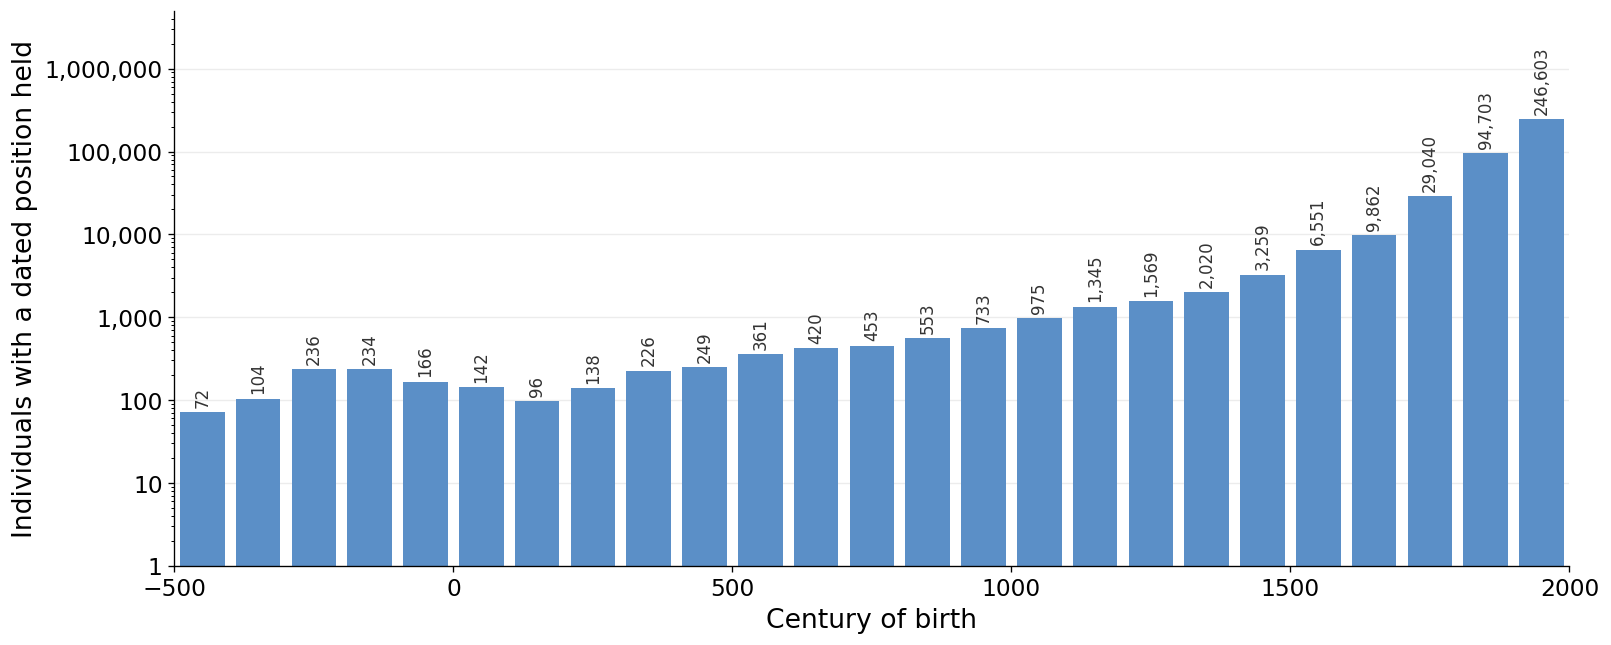

In [8]:
fig, ax = plt.subplots(figsize=FIGSIZE_WIDE)
ax.bar(per_century['century'] + CENTURY / 2, per_century['with a dated position'], width=CENTURY * 0.8, color=MAIN_COLOR)
for century, n in per_century.select('century', 'with a dated position').iter_rows():
    ax.text(century + CENTURY / 2, n * 1.15, f'{n:,}', ha='center', va='bottom', fontsize=VALUE_LABEL_FONTSIZE - 2, rotation=90, color=TEXT)
ax.set_yscale('log')
ax.yaxis.set_major_formatter(THOUSANDS)
ax.set_ylim(1, per_century['with a dated position'].max() * 20)
ax.set_xlim(FIRST_CENTURY, LAST_CENTURY + CENTURY)
ax.set_xlabel('Century of birth')
ax.set_ylabel('Individuals with a dated position held')
ax.grid(axis='y')
plt.show()

### Figure 2: Share of the individuals born in each century with a dated position held

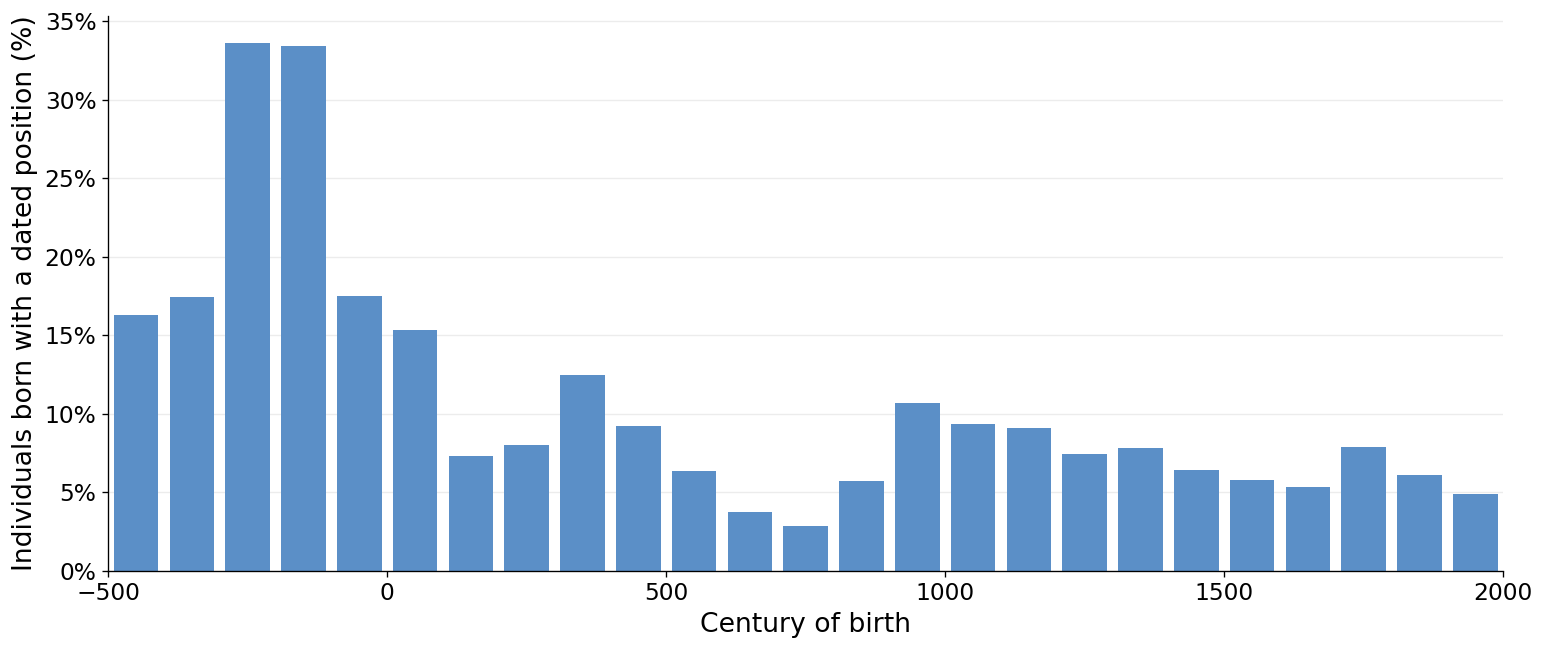

In [9]:
fig, ax = plt.subplots(figsize=FIGSIZE_WIDE)
ax.bar(per_century['century'] + CENTURY / 2, per_century['% of individuals born'], width=CENTURY * 0.8, color=MAIN_COLOR)
ax.set_xlim(FIRST_CENTURY, LAST_CENTURY + CENTURY)
ax.yaxis.set_major_formatter(PERCENT)
ax.set_xlabel('Century of birth')
ax.set_ylabel('Individuals born with a dated position (%)')
ax.grid(axis='y')
plt.show()

### Figure 3: Birth, positions held and death of the most-linked individuals born 700–799

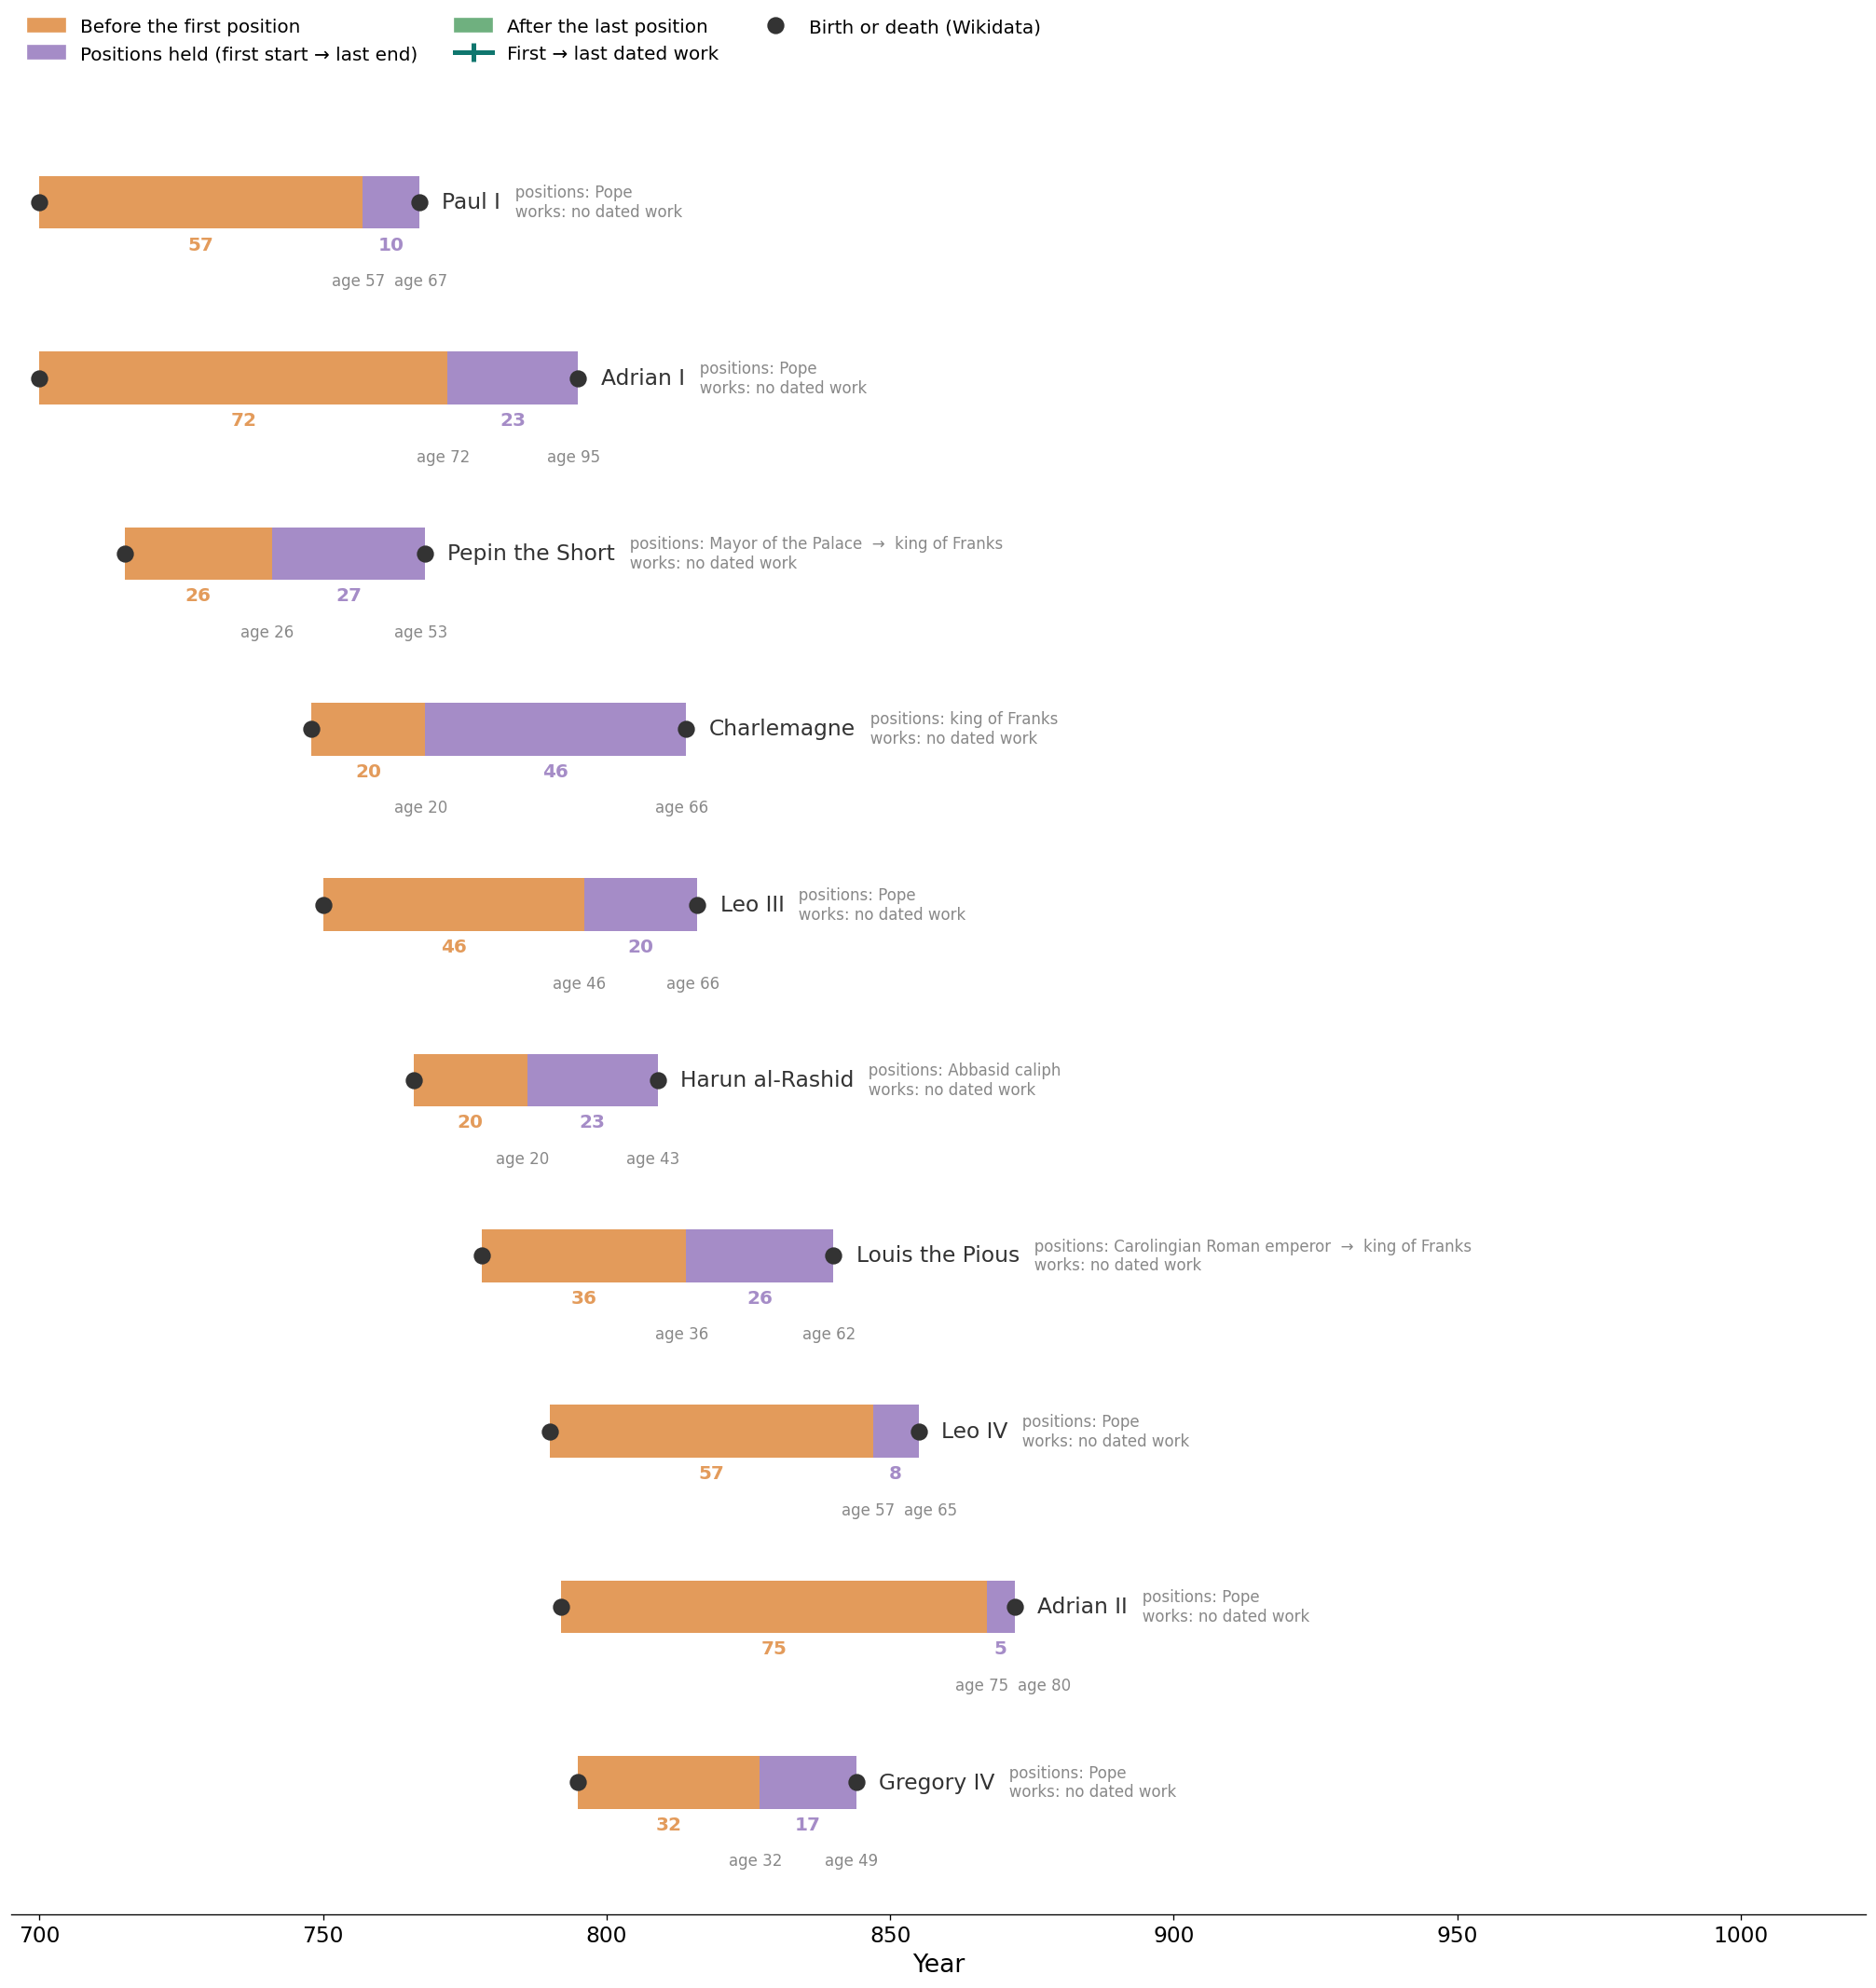

In [10]:
def shorten(text, size=45):
    return text if len(text) <= size else text[:size - 1] + '…'


def write_ages(ax, years, birth, y, va, color):
    right = None
    for year in sorted(set(years)):
        left = year - AGE_LABEL_WIDTH / 2 if right is None else max(year - AGE_LABEL_WIDTH / 2, right)
        ax.text(left, y, f'age {year - birth}', ha='left', va=va, fontsize=10, color=color)
        right = left + AGE_LABEL_WIDTH


def plot_lives(frame):
    fig, ax = plt.subplots(figsize=(17, 1.6 * frame.height + 2))
    for row, person in enumerate(frame.iter_rows(named=True)):
        birth = person['birth_year']
        spans = [(birth, person['first_position']), (person['first_position'], person['last_position']), (person['last_position'], person['death_year'])]
        for color, (start, end) in zip(SPAN_COLORS.values(), spans):
            if end > start:
                ax.barh(row, end - start, left=start, height=0.3, color=color)
                ax.text((start + end) / 2, row - 0.19, end - start, ha='center', va='top', fontsize=12, color=color, fontweight='bold')
        write_ages(ax, [person['first_position'], person['last_position'], person['death_year']], birth, row - 0.4, 'top', MUTED_TEXT)
        has_works = person['peak_source'] == 'dated works'
        if has_works:
            ax.plot([person['peak_start'], person['peak_end'] + 1], [row + 0.27] * 2, color=TEAL, linewidth=3, marker='|', markersize=12, markeredgewidth=3)
            write_ages(ax, [person['peak_start'], person['peak_end']], birth, row + 0.35, 'bottom', TEAL)
        for year in (person['birth_year'], person['death_year']):
            ax.plot(year, row, 'o', markersize=10, color=TEXT, zorder=3)
        name = ax.text(max(person['death_year'], person['last_position'], person['peak_end'] if has_works else person['death_year']) + 4, row, person['name'], va='center', fontsize=14, color=TEXT)
        positions = person['first_position_name'] if person['first_position_qid'] == person['last_position_qid'] else f"{person['first_position_name']}  →  {person['last_position_name']}"
        works = 'no dated work' if person['first_work_name'] is None else (
            person['first_work_name'] if person['first_work_name'] == person['last_work_name'] else f"{shorten(person['first_work_name'])}  →  {shorten(person['last_work_name'])}"
        )
        ax.annotate(f'   positions: {positions}\n   works: {works}', xycoords=name, xy=(1, 0.5), va='center', fontsize=10, color=MUTED_TEXT)
    ax.legend(handles=[
        *[Patch(color=color, label=label) for label, color in SPAN_COLORS.items()],
        Line2D([], [], color=TEAL, linewidth=3, marker='|', markersize=12, markeredgewidth=3, label='First → last dated work'),
        Line2D([], [], marker='o', linestyle='', markersize=10, color=TEXT, label='Birth or death (Wikidata)'),
    ], loc='lower left', bbox_to_anchor=(0, 1), ncol=3, fontsize=12)
    ax.set_yticks([])
    ax.spines['left'].set_visible(False)
    ax.set_ylim(-0.75, frame.height - 0.3)
    ax.set_xlim(frame['birth_year'].min() - 5, frame['death_year'].max() + 150)
    ax.set_xlabel('Year')
    plt.tight_layout()
    plt.show()


plot_lives(examples['everyone'])

### Figure 4: Birth, positions held, dated works and death of the most-linked scientists born 1600–1699

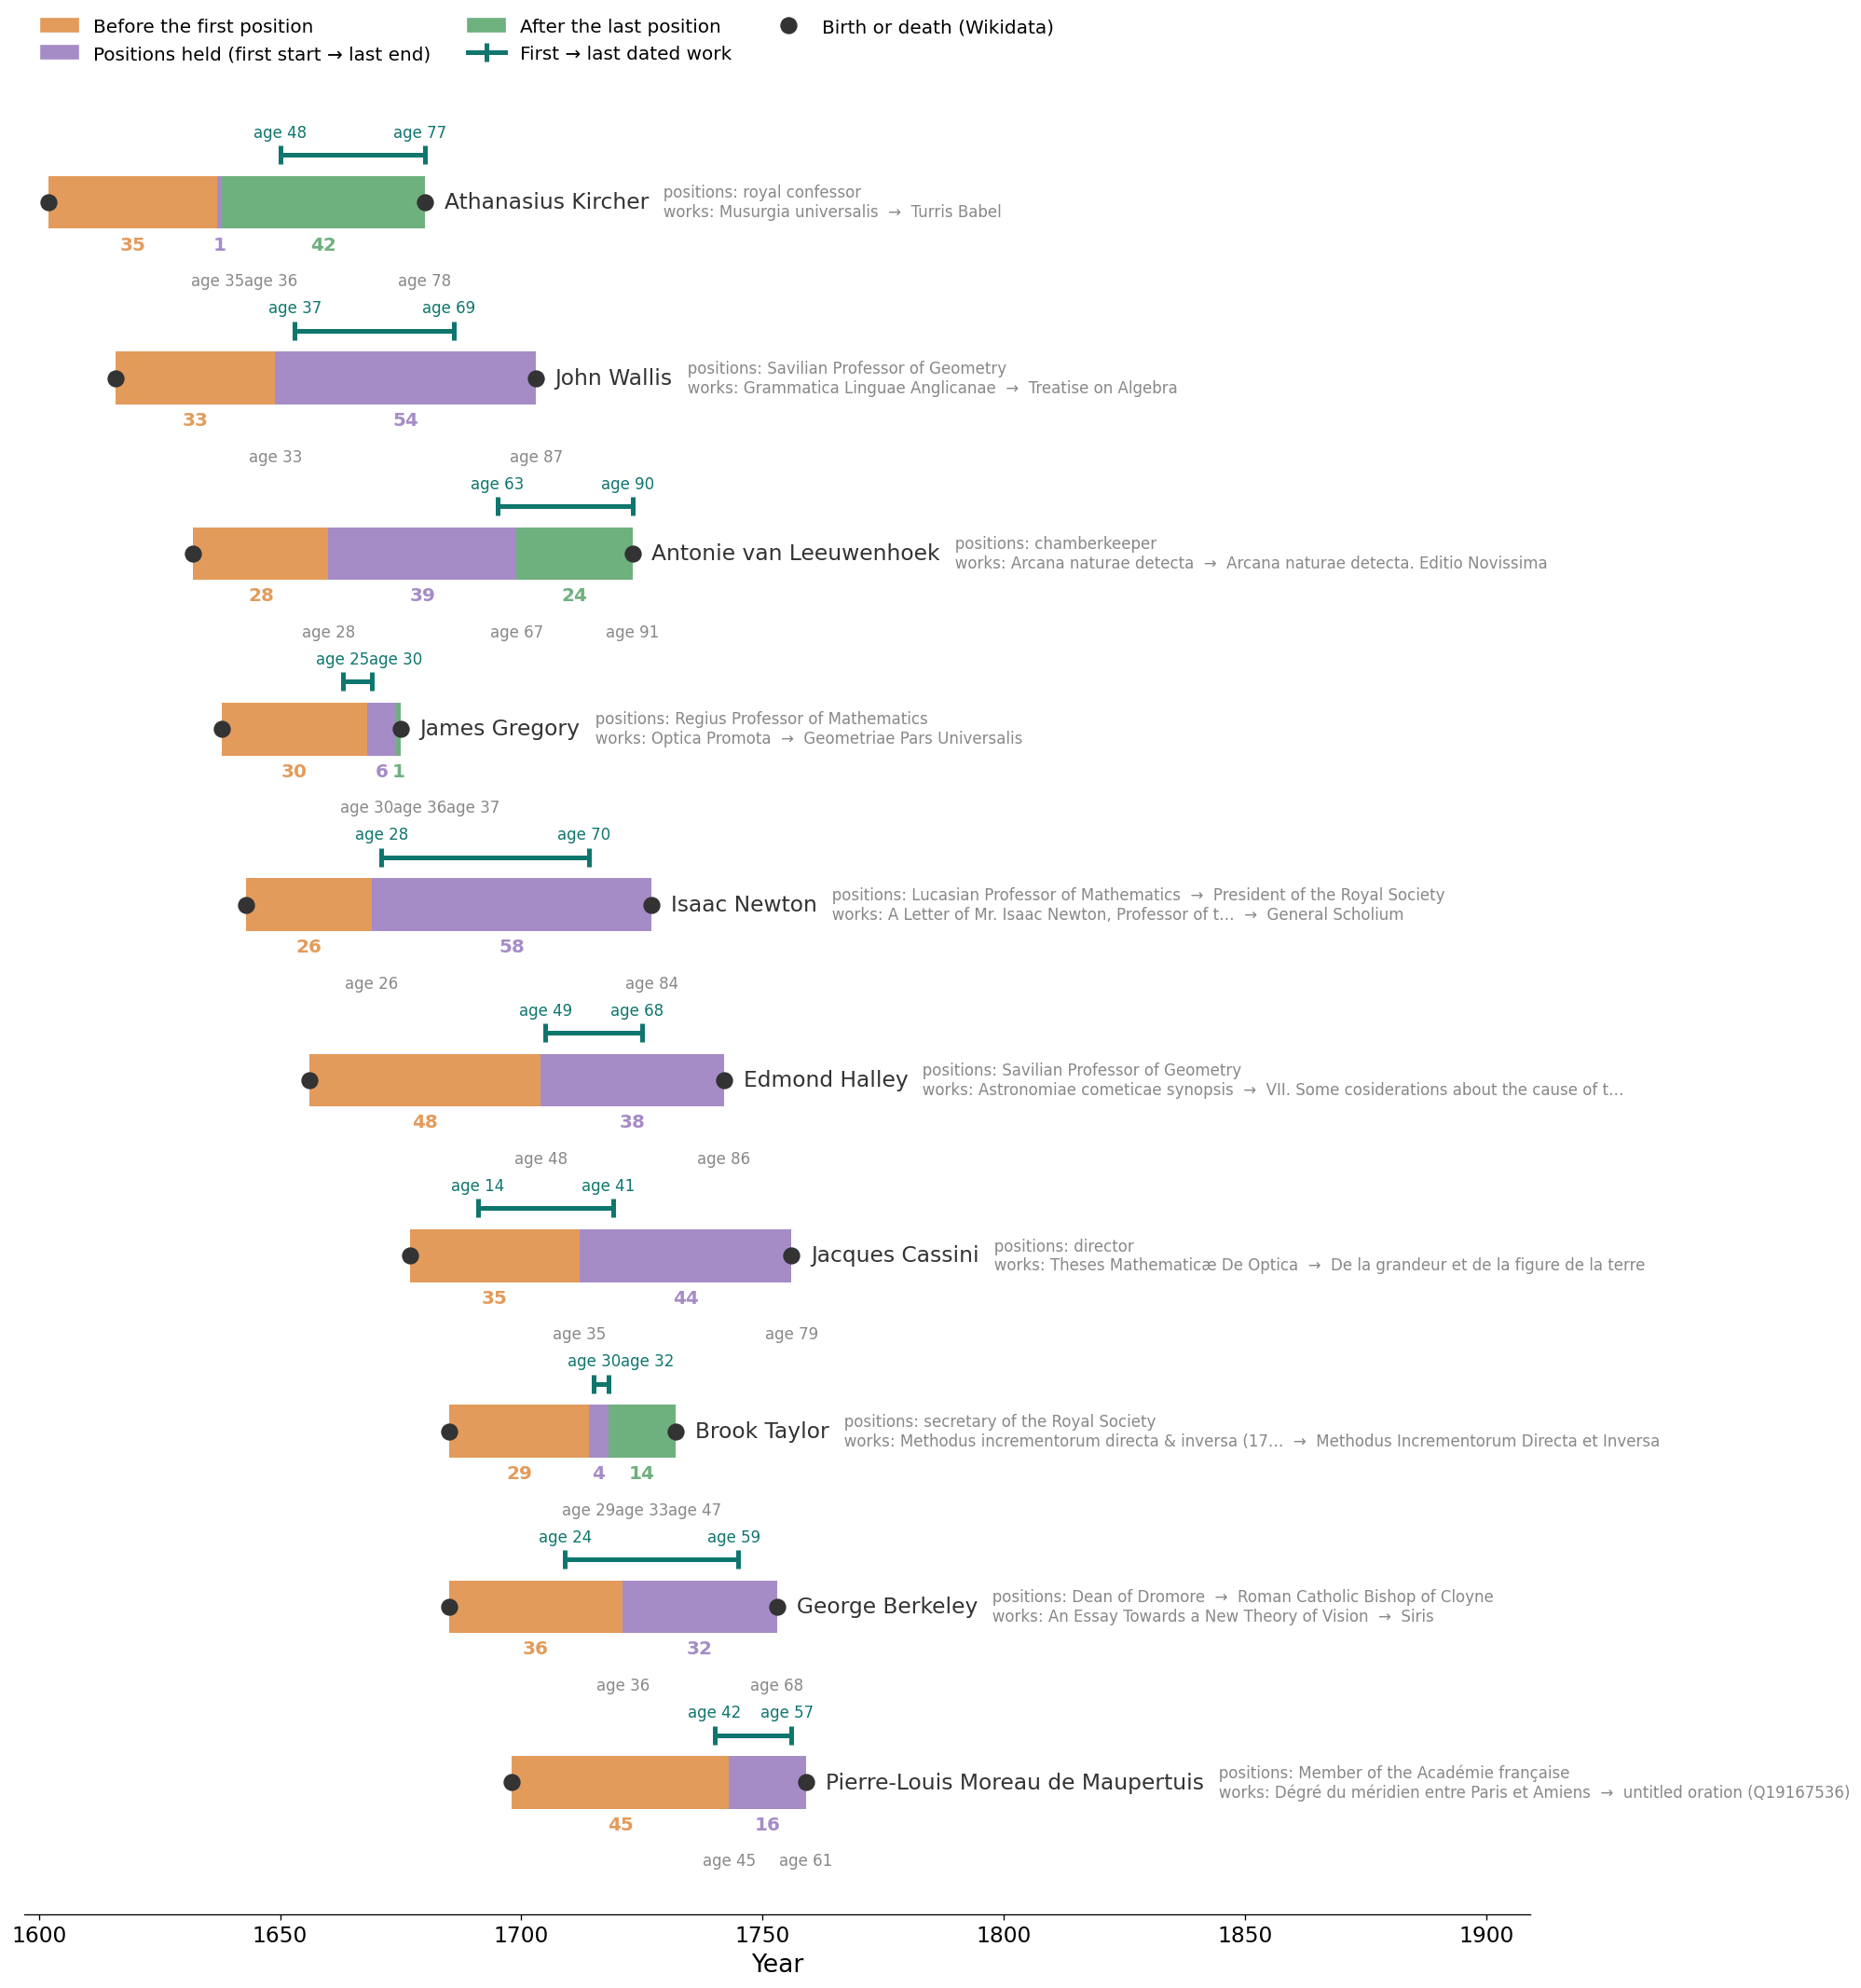

In [11]:
plot_lives(examples['scientists'])

### Figure 5: Birth, positions held, dated works and death of the most-linked artists born 1600–1699

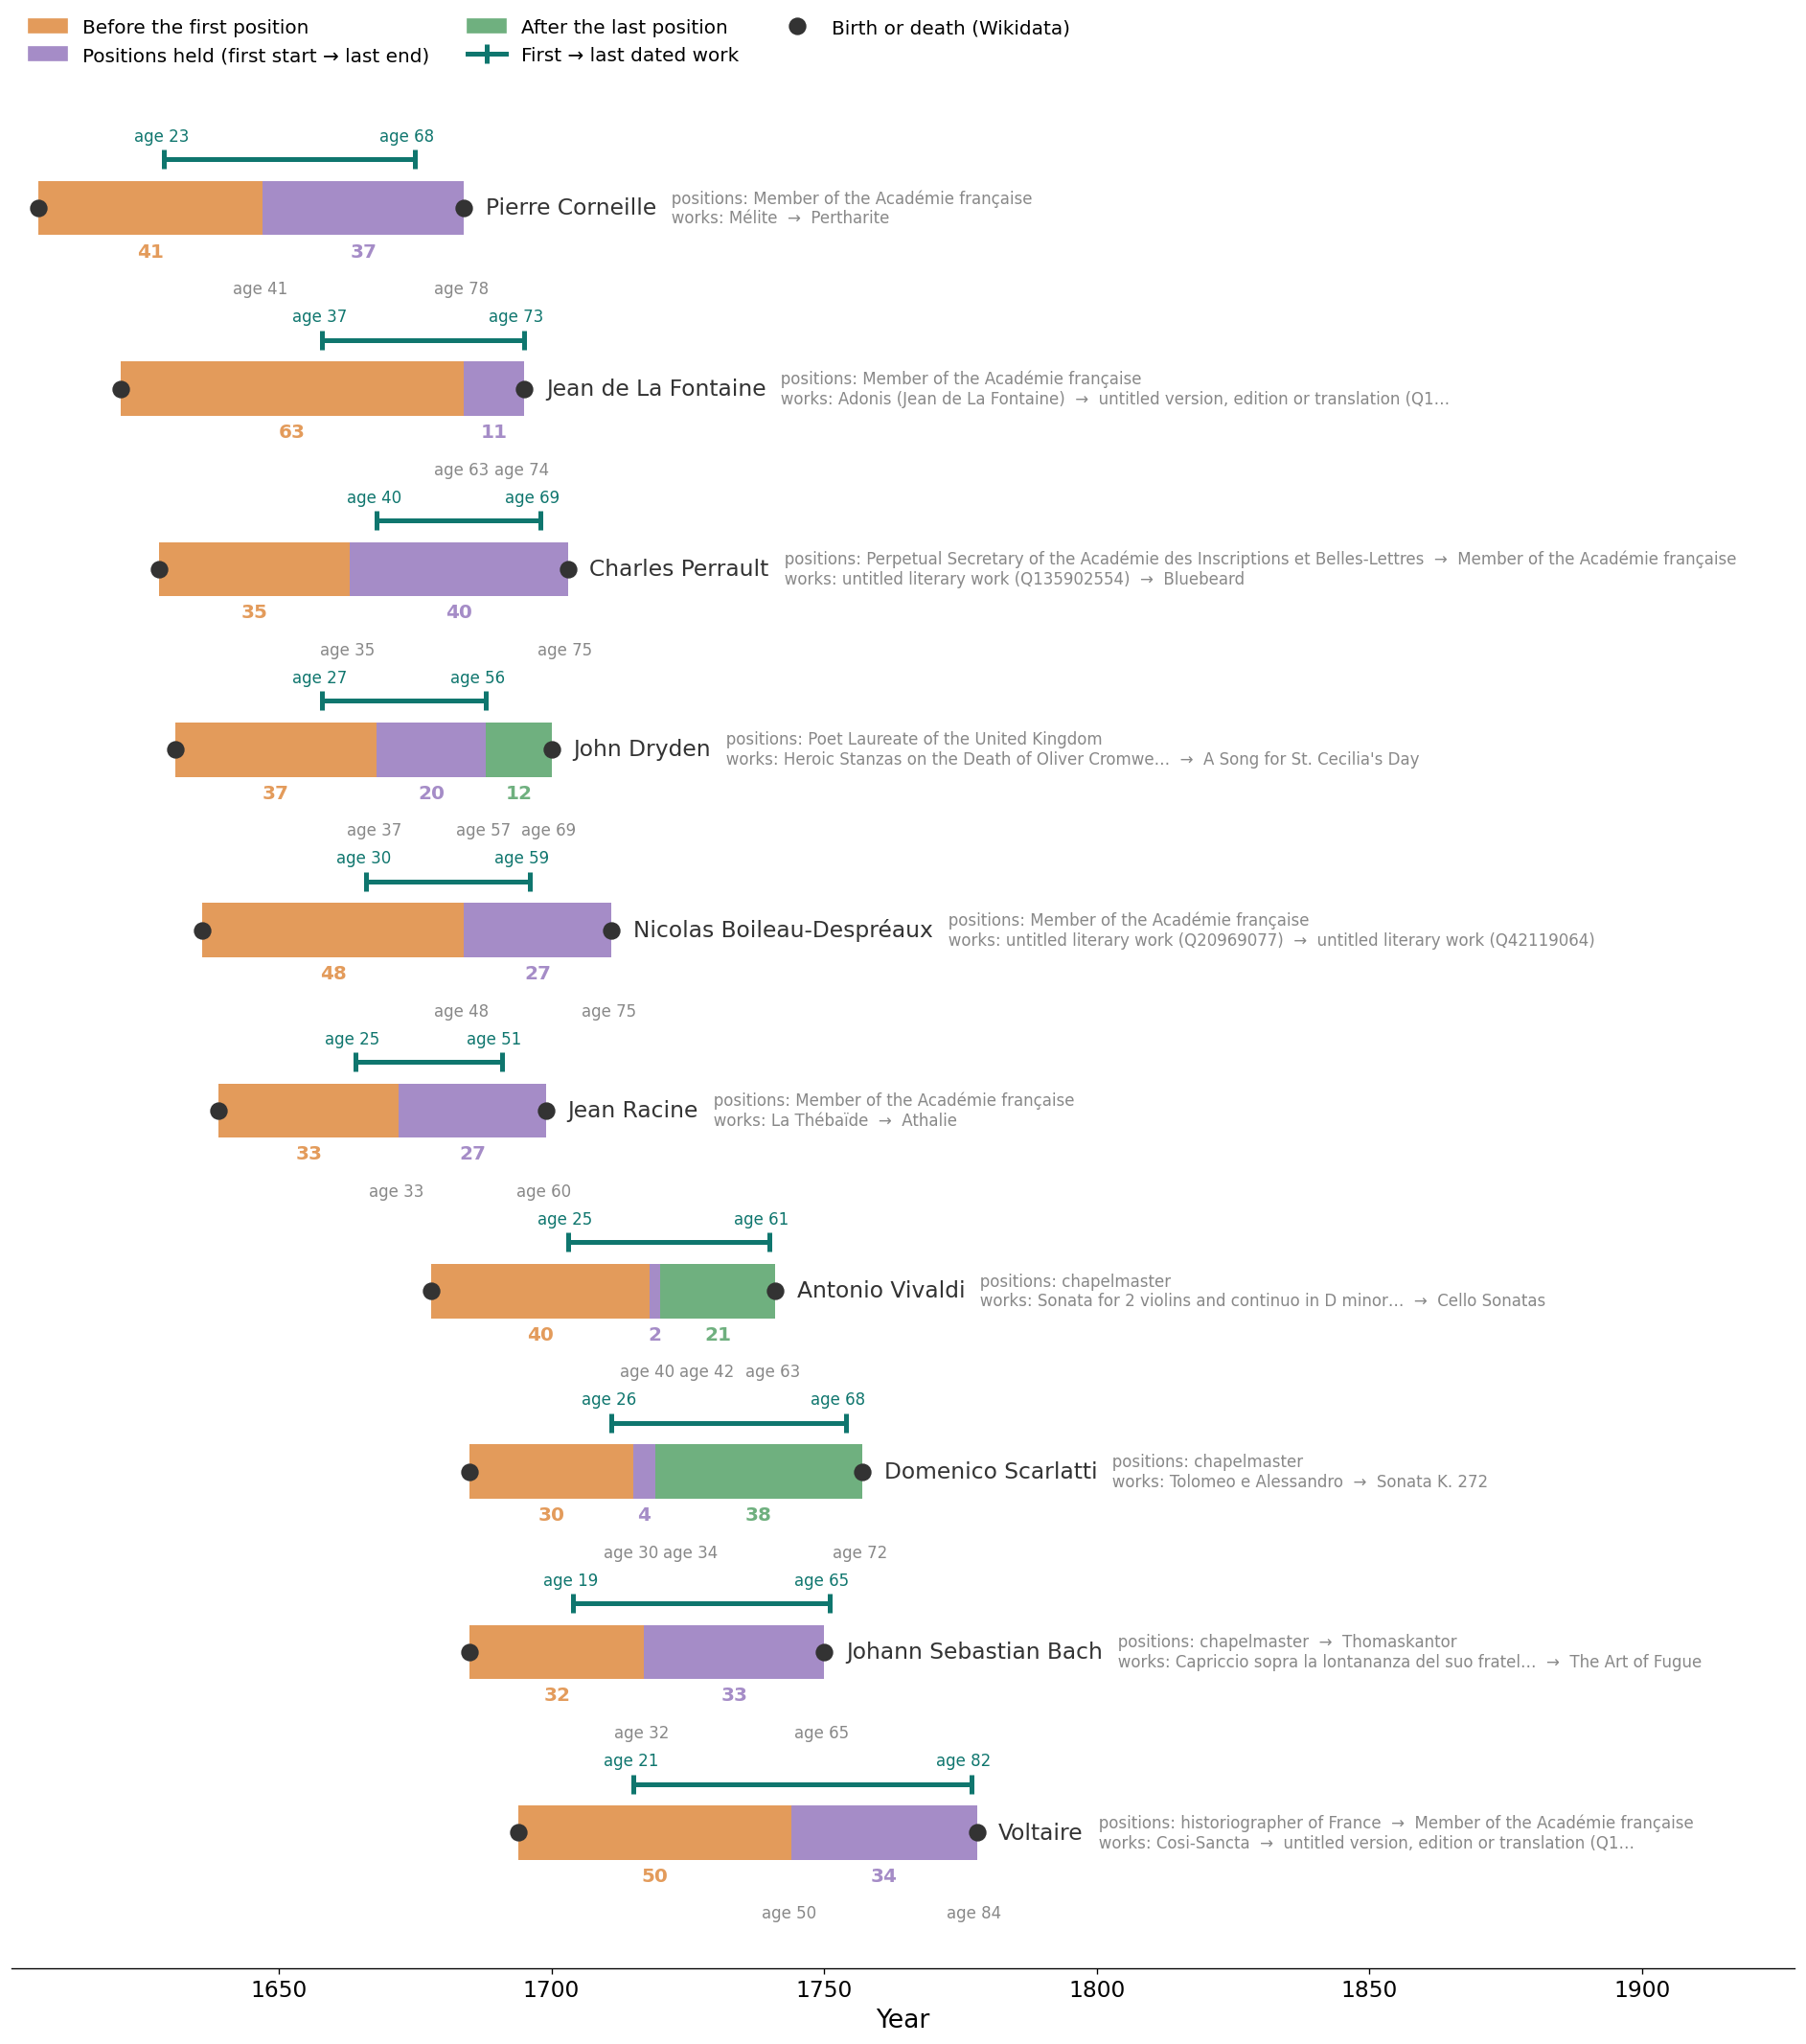

In [12]:
plot_lives(examples['artists'])

### Figures 6–8: Chronology of the scientists, artists and leaders born 1600–1699

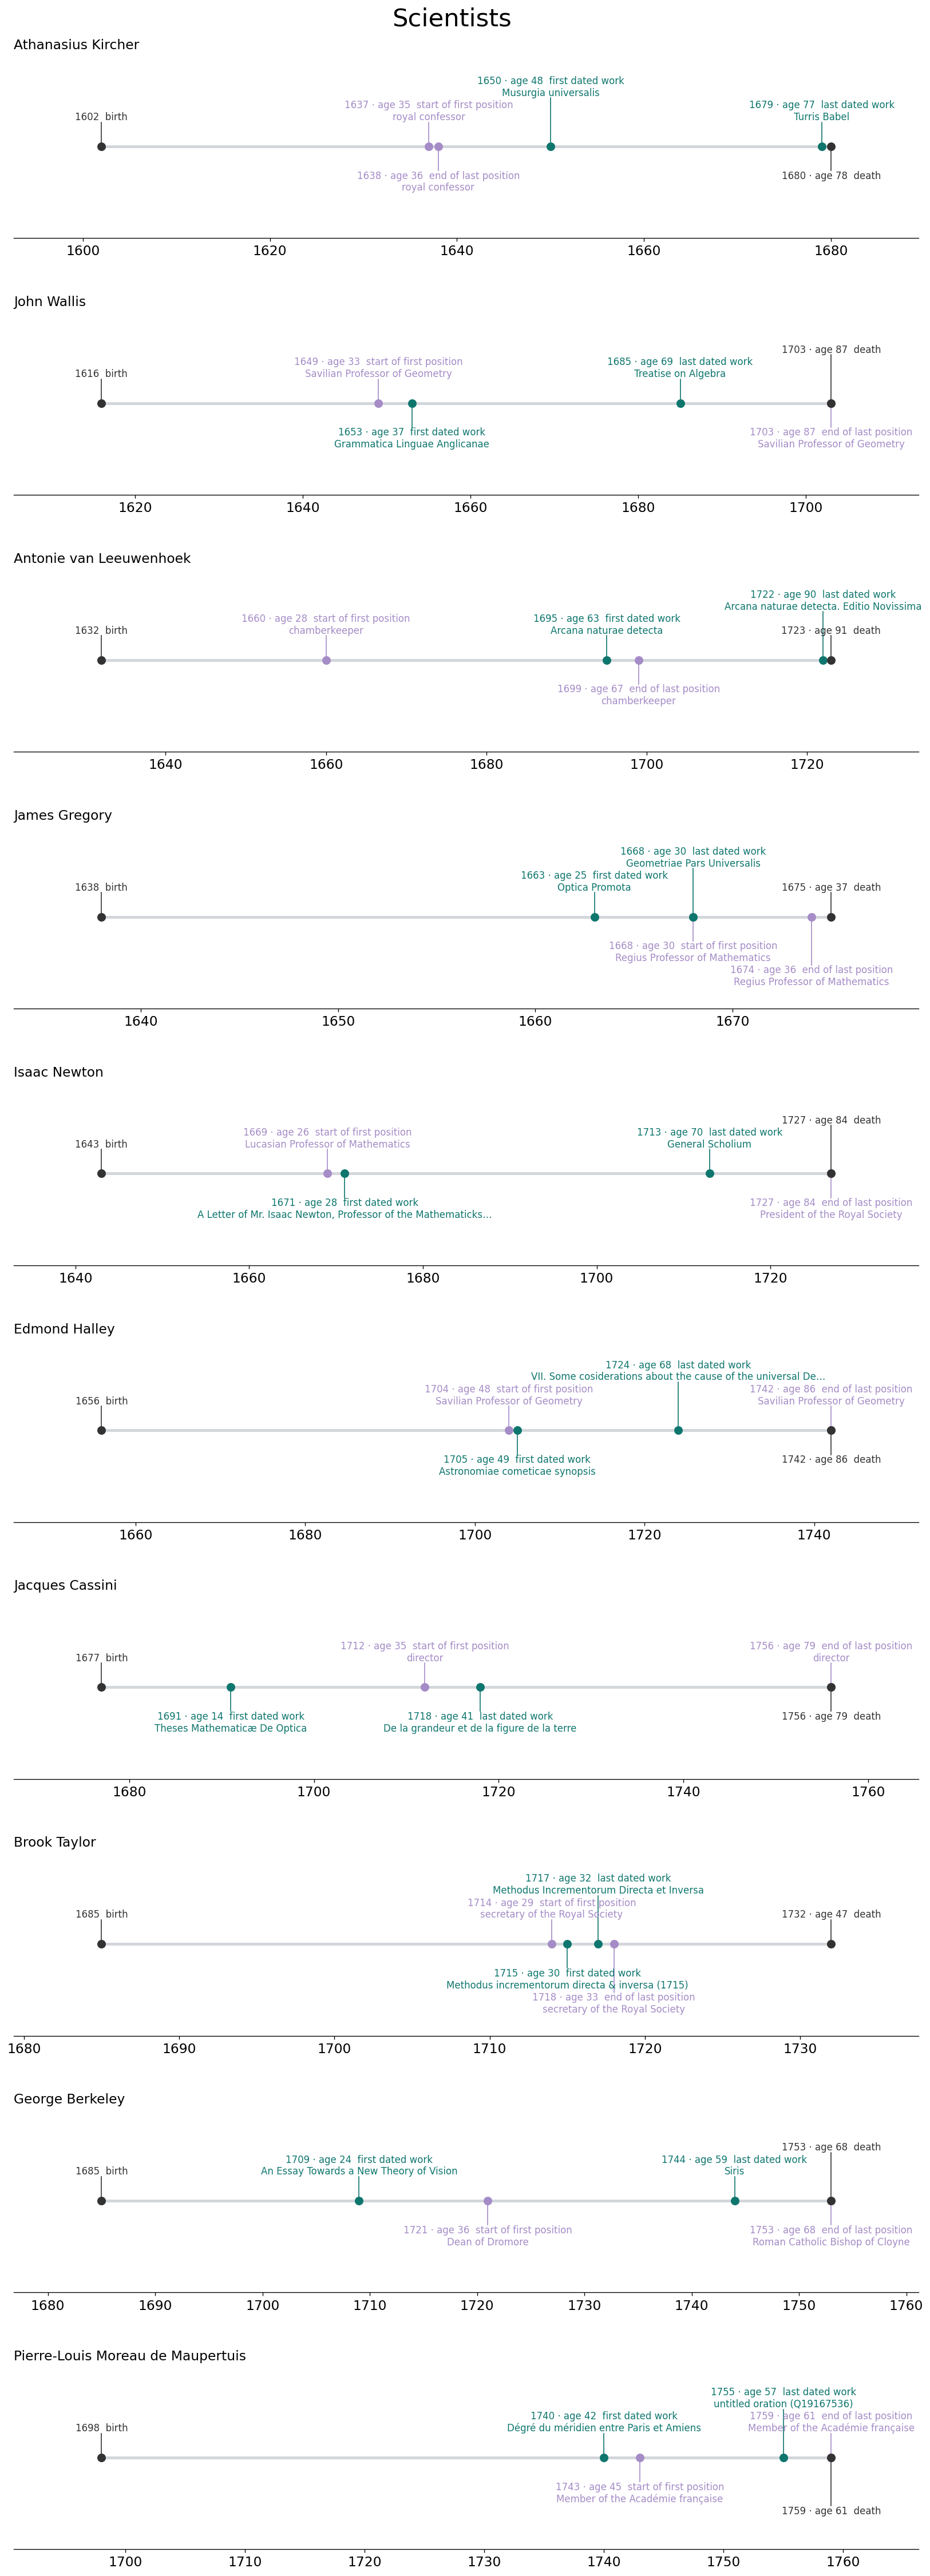

In [13]:
def events(person):
    found = [('Birth', person['birth_year'], None),
             ('Start of first position', person['first_position'], person['first_position_name']),
             ('End of last position', person['last_position'], person['last_position_name'])]
    if person['peak_source'] == 'dated works':
        found += [('First dated work', person['peak_start'], person['first_work_name']), ('Last dated work', person['peak_end'], person['last_work_name'])]
    found.append(('Death', person['death_year'], None))
    return sorted(found, key=lambda event: (event[1], list(EVENT_COLORS).index(event[0])))


def label_levels(found, lifetime):
    last_year = {}
    levels = []
    for _, year, _ in found:
        free = [level for level in EVENT_LEVELS if level not in last_year or year - last_year[level] > LABEL_SPAN * lifetime]
        level = free[0] if free else min(EVENT_LEVELS, key=lambda level: last_year[level])
        last_year[level] = year
        levels.append(level)
    return levels


def plot_chronology(frame, title):
    people = frame.sort('birth_year')
    fig, axes = plt.subplots(people.height, 1, figsize=(17, 3.8 * people.height), gridspec_kw={'hspace': 0.4})
    fig.subplots_adjust(top=1 - 0.9 / (3.8 * people.height), bottom=0.02)
    for ax, person in zip(axes, people.iter_rows(named=True)):
        birth, death = person['birth_year'], person['death_year']
        ax.plot([birth, death], [0, 0], color=LIGHT_GREY, linewidth=3, zorder=1)
        found = events(person)
        for (event, year, name), level in zip(found, label_levels(found, death - birth)):
            color = EVENT_COLORS[event]
            level *= LEVEL_HEIGHT
            ax.plot([year, year], [0, level], color=color, linewidth=1, zorder=1)
            ax.plot(year, 0, 'o', color=color, markersize=8, zorder=2)
            age = '' if event == 'Birth' else f' · age {year - birth}'
            label = f"{year}{age}  {event.lower()}" + (f"\n{shorten(name, 60)}" if name else '')
            ax.text(year, level, label, ha='center', va='bottom' if level > 0 else 'top', fontsize=10, color=color)
        no_works = '' if person['peak_source'] == 'dated works' else '   (no dated work)'
        ax.set_title(person['name'] + no_works, loc='left', fontsize=14, color='black')
        ax.set_ylim(-3.8 * LEVEL_HEIGHT, 3.8 * LEVEL_HEIGHT)
        ax.set_xlim(birth - 0.12 * (death - birth), death + 0.12 * (death - birth))
        ax.set_yticks([])
        for side in ('left', 'top', 'right'):
            ax.spines[side].set_visible(False)
    fig.suptitle(title, fontsize=POLITY_TITLE_FONTSIZE, color='black', y=1 - 0.2 / (3.8 * people.height))
    plt.show()


plot_chronology(examples['scientists'], 'Scientists')

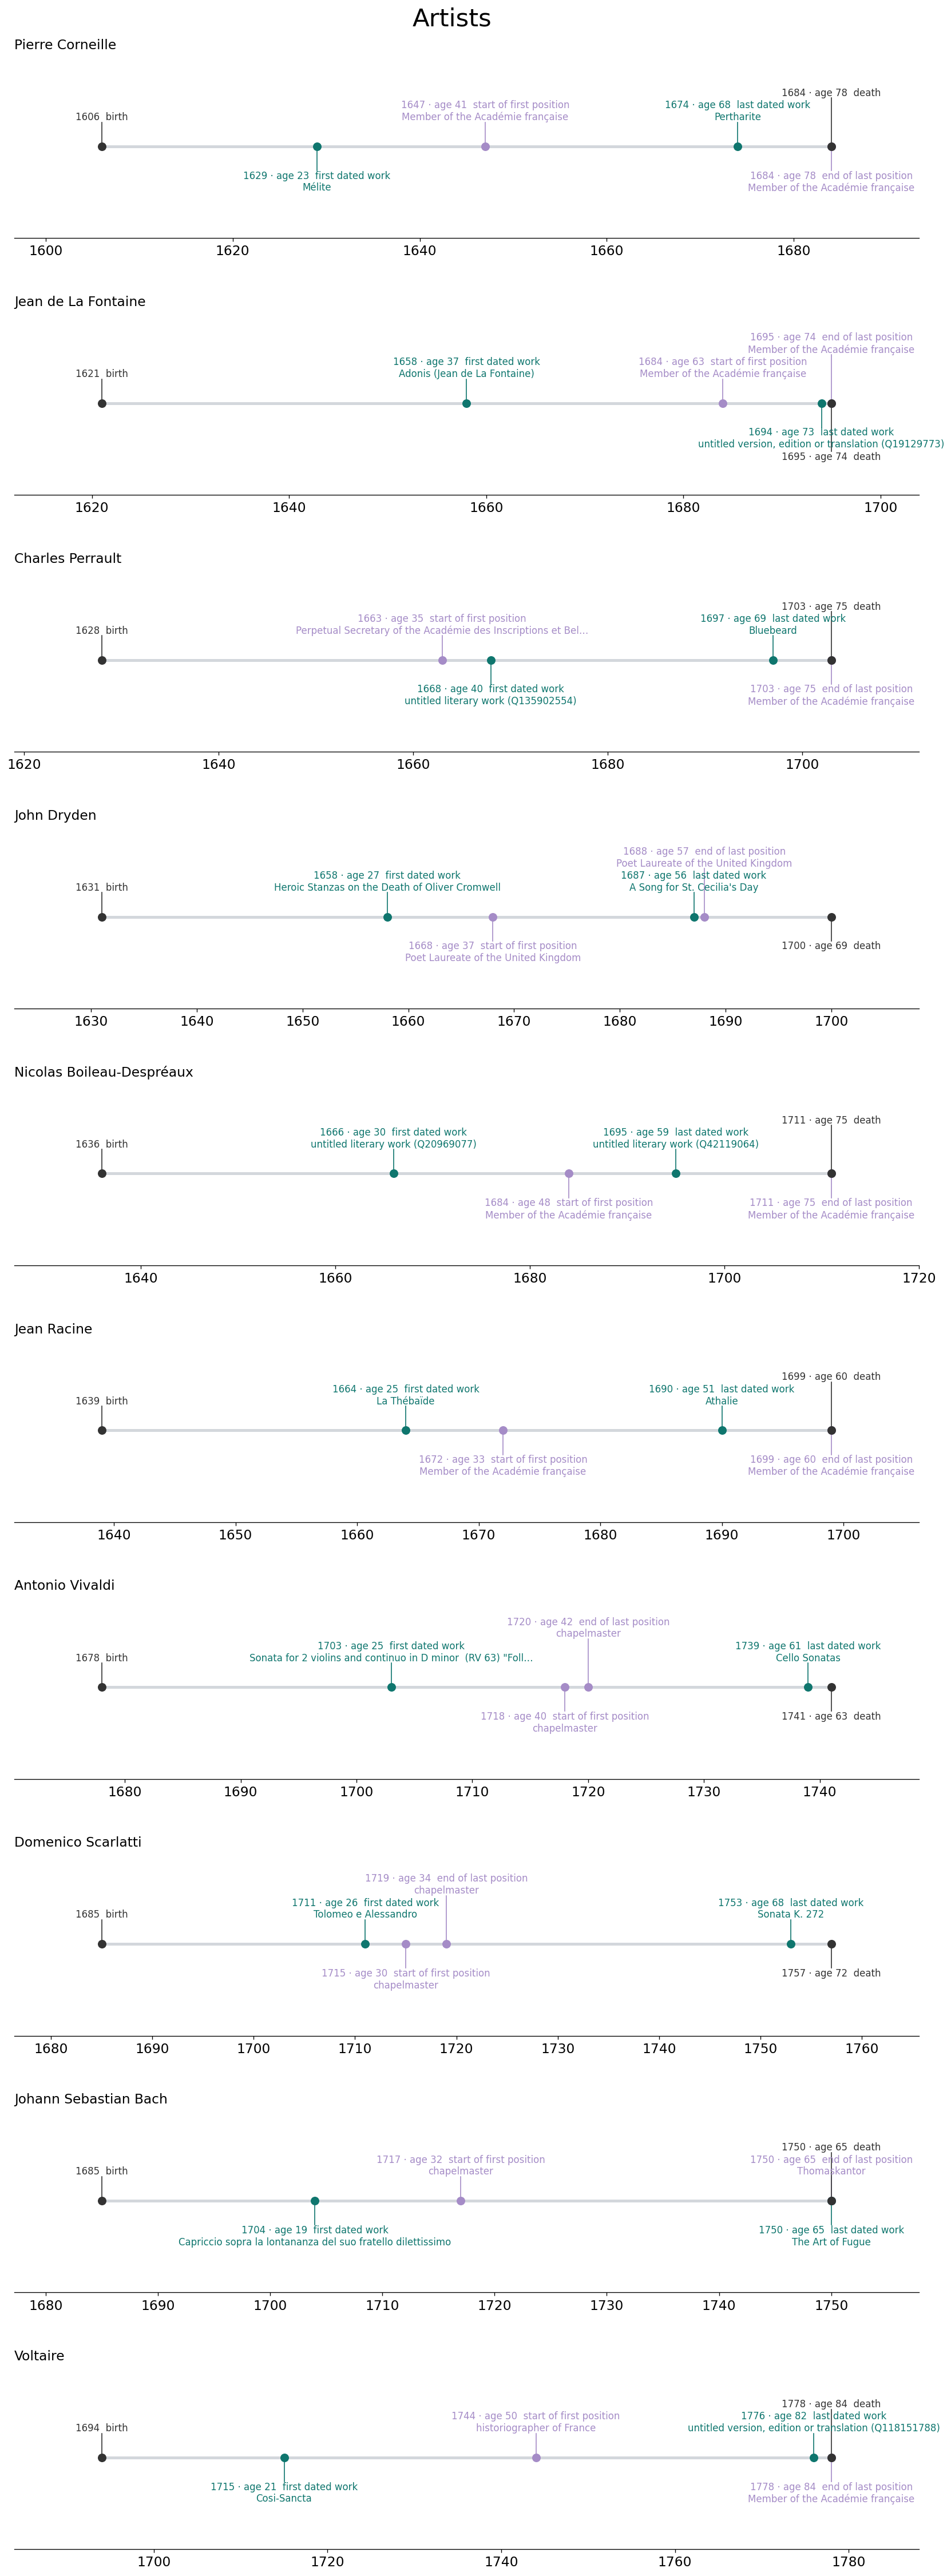

In [14]:
plot_chronology(examples['artists'], 'Artists')

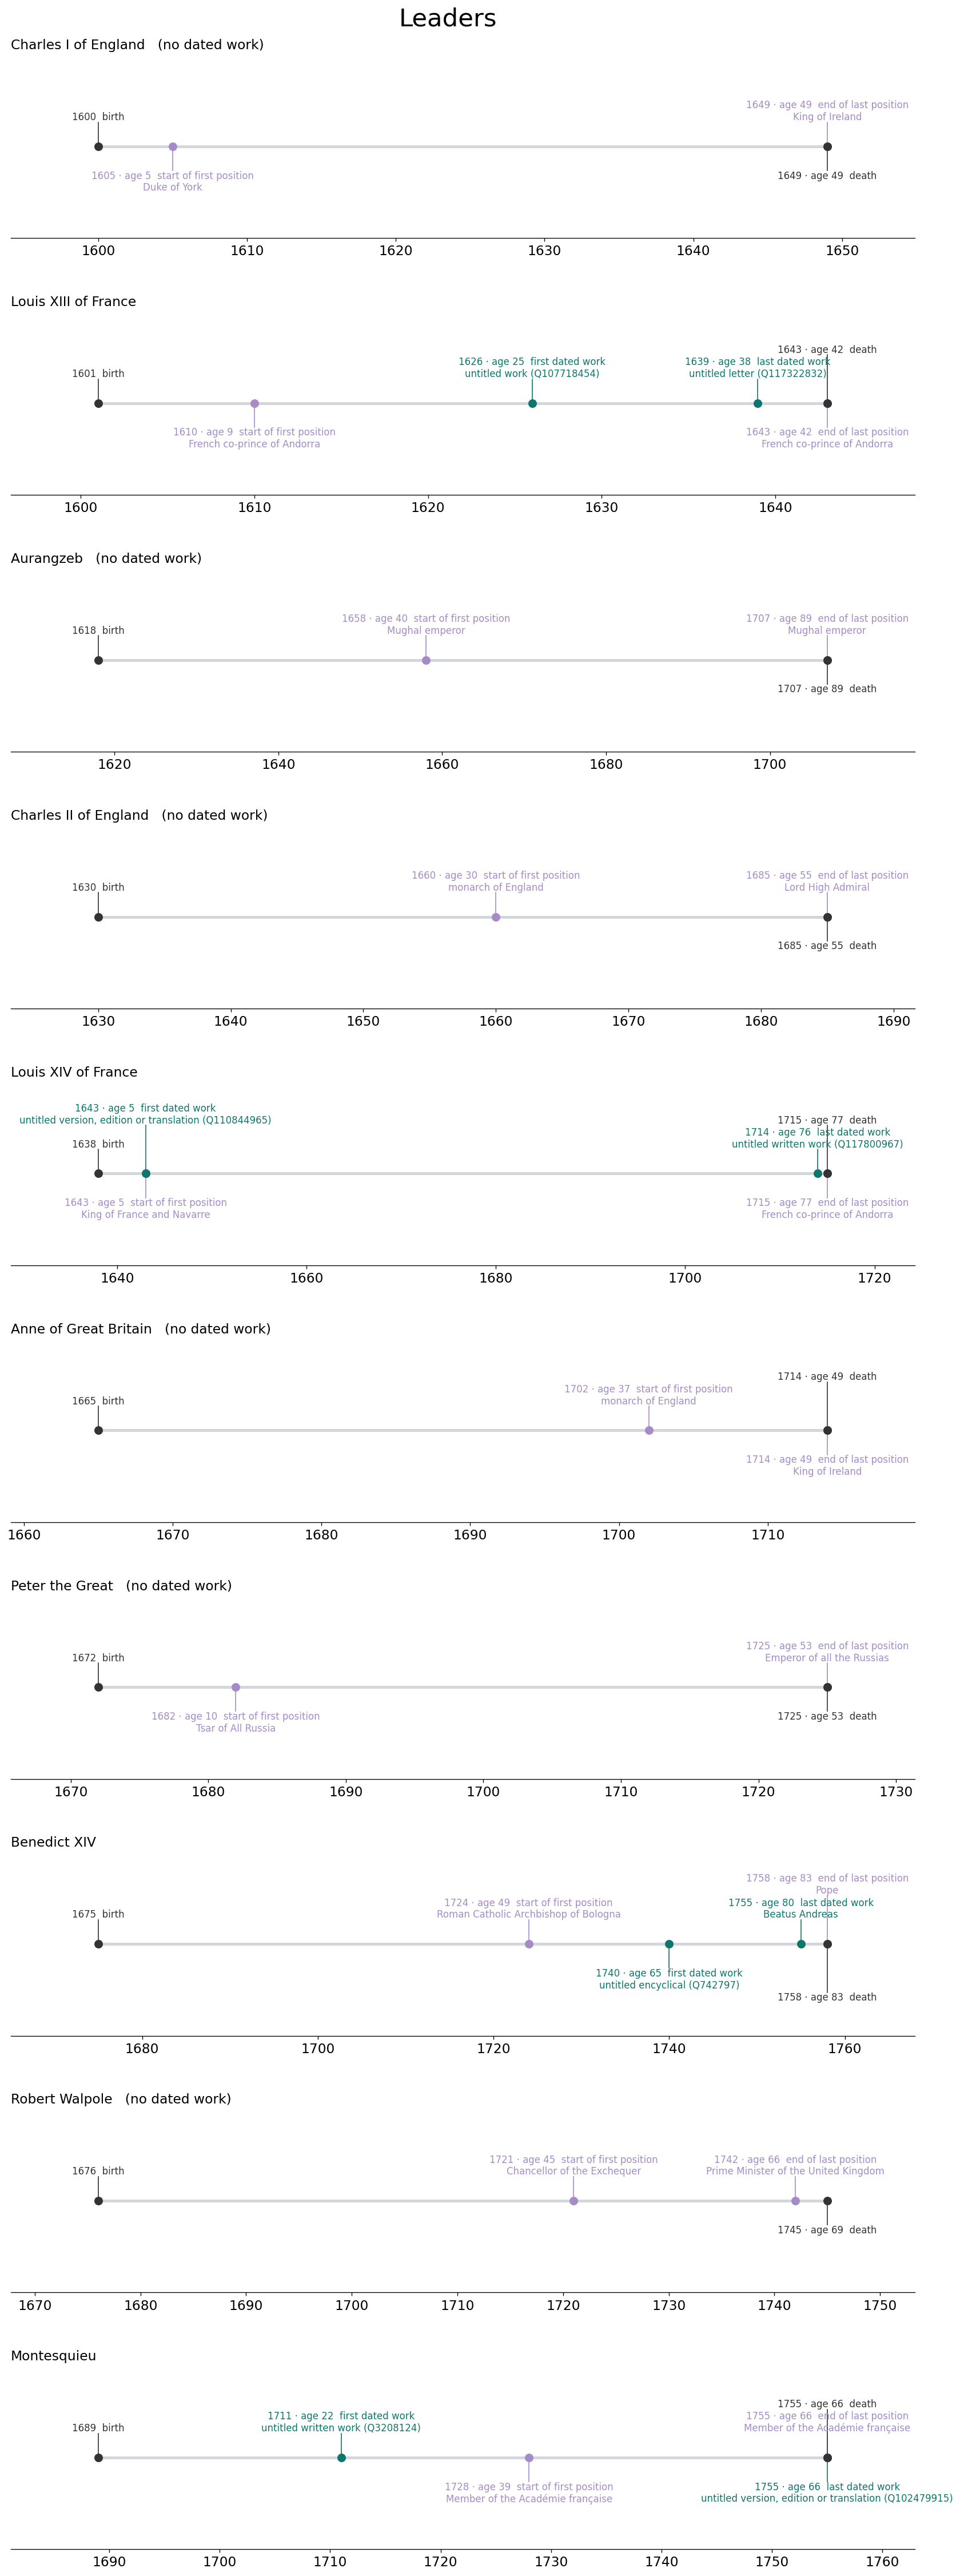

In [15]:
plot_chronology(examples['leaders'], 'Leaders')

### Figure 9: First work and first position of individuals born 1500–1599 in Europe and China

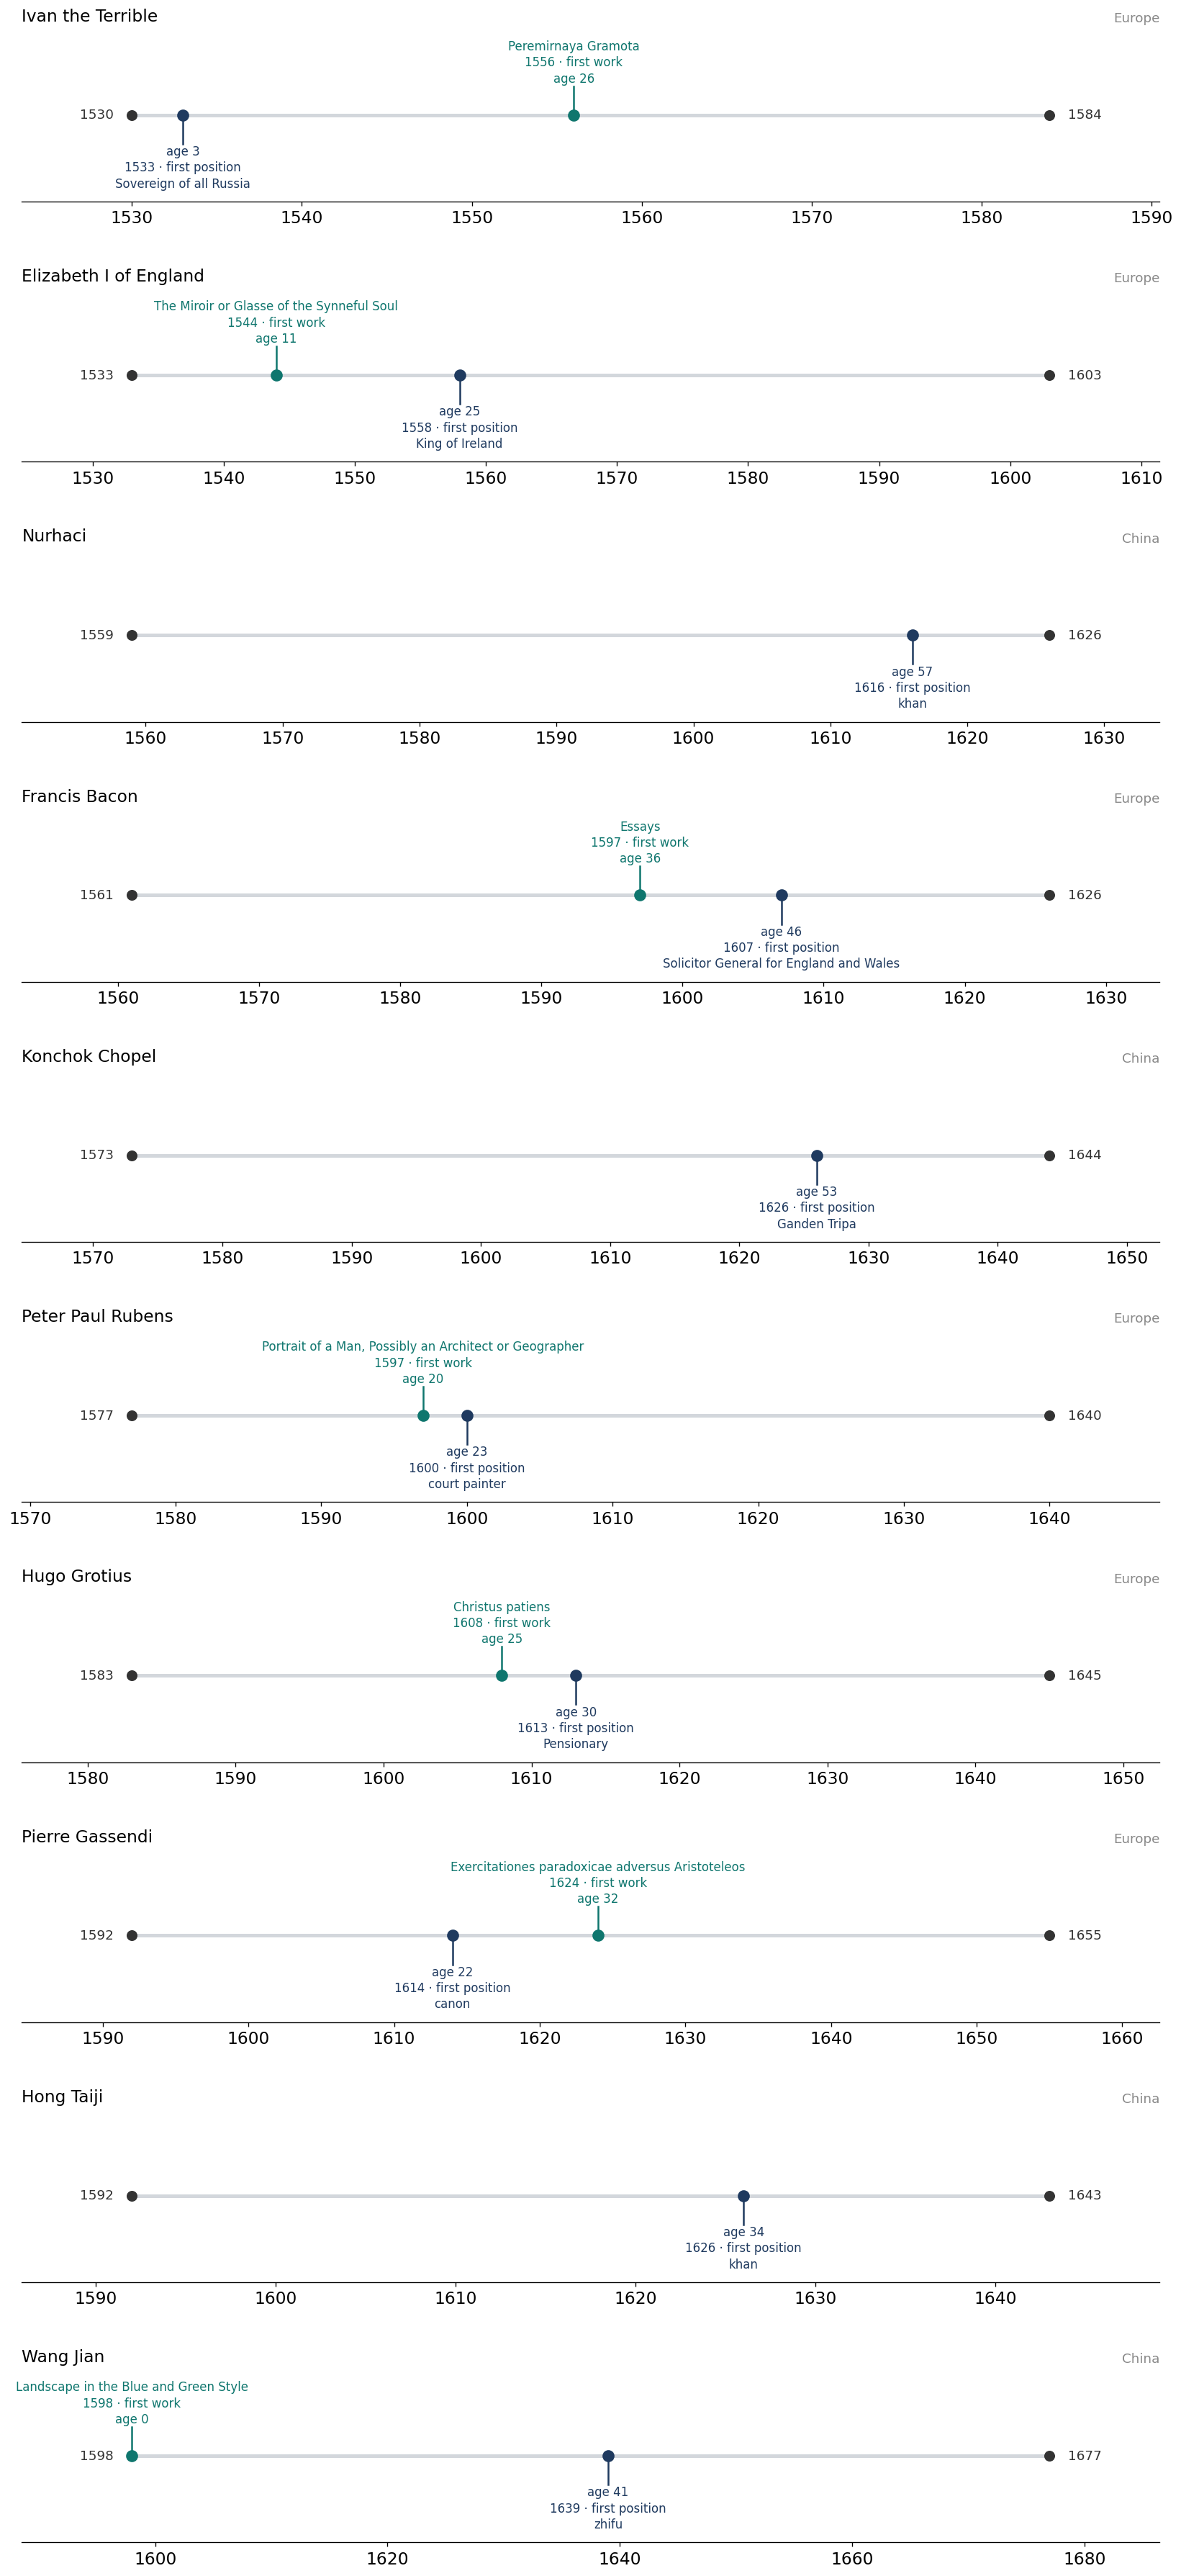

In [16]:
def plot_milestones(frame):
    people = frame.sort('birth_year')
    fig, axes = plt.subplots(people.height, 1, figsize=(17, 3 * people.height), gridspec_kw={'hspace': 0.5})
    fig.subplots_adjust(top=0.99, bottom=0.02)
    for ax, person in zip(axes, people.iter_rows(named=True)):
        birth, death = person['birth_year'], person['death_year']
        ax.plot([birth, death], [0, 0], color=LIGHT_GREY, linewidth=3, zorder=1)
        for year, ha, shift in [(birth, 'right', -1), (death, 'left', 1)]:
            ax.plot(year, 0, 'o', color=TEXT, markersize=8, zorder=2)
            ax.text(year + shift * 0.02 * (death - birth), 0, year, ha=ha, va='center', fontsize=11, color=TEXT)
        milestones = [('first position', person['first_position'], person['first_position_name'], -1)]
        titled = person['peak_source'] == 'dated works' and person['first_work_name'] and not person['first_work_name'].startswith('untitled')
        if titled:
            milestones.append(('first work', person['peak_start'], person['first_work_name'], 1))
        for event, year, name, side in milestones:
            color = MILESTONE_COLORS[event]
            ax.plot([year, year], [0, side * 1.2], color=color, linewidth=1.5, zorder=1)
            ax.plot(year, 0, 'o', color=color, markersize=9, zorder=3)
            lines = [f'age {year - birth}', f'{year} · {event}', shorten(name, 60)]
            ax.text(year, side * 1.25, '\n'.join(lines if side < 0 else lines[::-1]), ha='center', va='top' if side < 0 else 'bottom', fontsize=10, color=color, linespacing=1.3)
        name = ax.set_title(person['name'], loc='left', fontsize=14, color='black')
        ax.text(1, 1.02, person['region'], transform=ax.transAxes, ha='right', va='bottom', fontsize=11, color=MUTED_TEXT)
        ax.set_ylim(-3.6, 3.6)
        ax.set_xlim(birth - 0.12 * (death - birth), death + 0.12 * (death - birth))
        ax.set_yticks([])
        for side in ('left', 'top', 'right'):
            ax.spines[side].set_visible(False)
    plt.show()


plot_milestones(examples['mixed'])

### Figure 10: Individuals with a dated position, dated works, or both, per century of birth

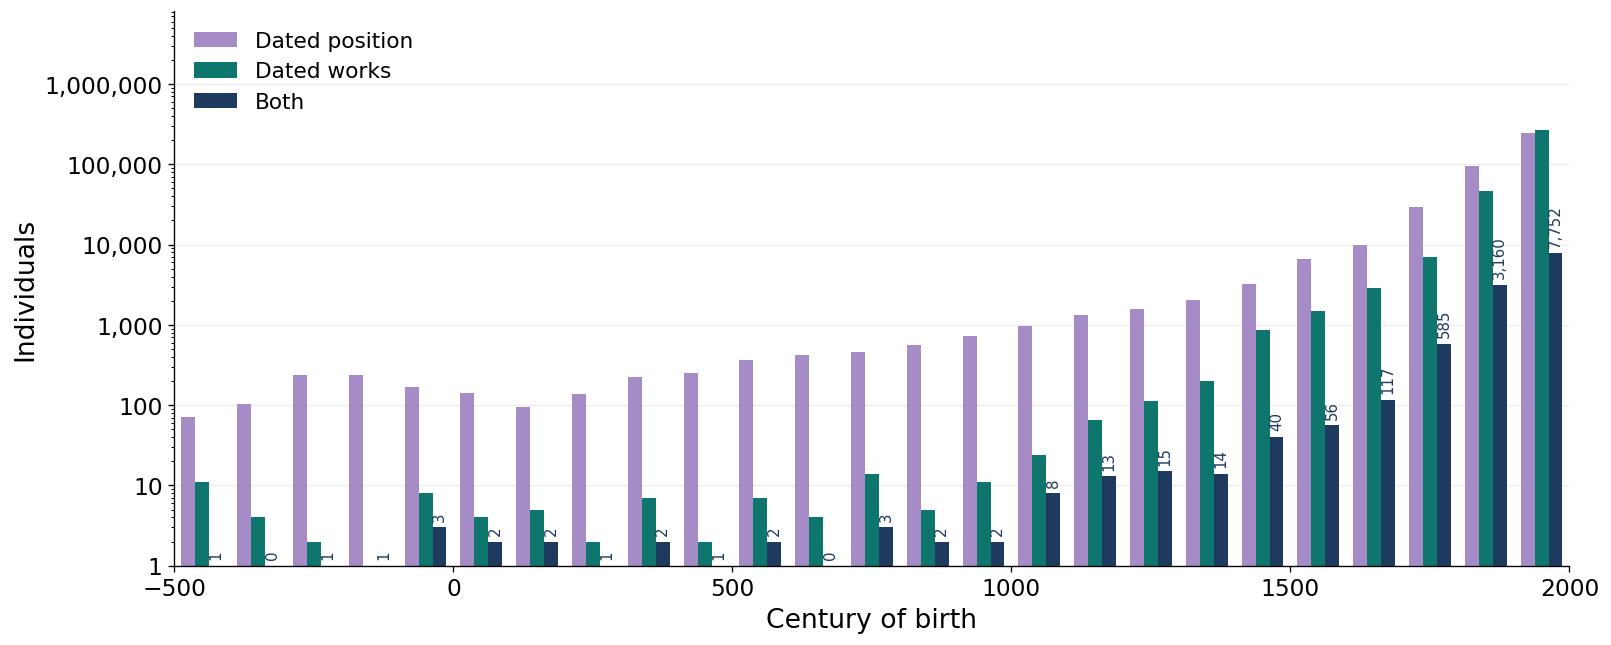

In [17]:
BOTH_COLORS = {'dated position': PURPLE, 'dated works': TEAL, 'both': NAVY}
fig, ax = plt.subplots(figsize=FIGSIZE_WIDE)
width = CENTURY / (len(BOTH_COLORS) + 1)
for i, (column, color) in enumerate(BOTH_COLORS.items()):
    ax.bar(position_and_works['century'] + width * (i + 1), position_and_works[column], width=width, color=color, label=column.capitalize())
for century, n in position_and_works.select('century', 'both').iter_rows():
    ax.text(century + width * 3, max(n, 1) * 1.2, f'{n:,}', ha='center', va='bottom', fontsize=VALUE_LABEL_FONTSIZE - 3, rotation=90, color=NAVY)
ax.set_yscale('log')
ax.yaxis.set_major_formatter(THOUSANDS)
ax.set_ylim(1, position_and_works['dated works'].max() * 30)
ax.set_xlim(FIRST_CENTURY, LAST_CENTURY + CENTURY)
ax.set_xlabel('Century of birth')
ax.set_ylabel('Individuals')
ax.grid(axis='y')
ax.legend(loc='upper left')
plt.show()